# E110 · Is the bar for a search the same for everyone? The threshold test on 856,000 Raleigh traffic stops

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify |
| **Data** | Real: **Stanford Open Policing Project**, Raleigh, North Carolina city file (release of 2020-04-01; Pierson et al. 2020): 856,400 vehicular stops by the Raleigh Police Department, 2002-2015, with the driver's race, whether the driver or the car was searched, on what basis, and whether contraband was found. Licensed under the **Open Data Commons Attribution License (ODC-By) v1.0**; attribution: Stanford Open Policing Project. `tools/build_e110_raleigh.py` streams the 13.5 MB zip into counts of stops, searches and hits by city, year and officer (hashed ids) and race |
| **You will learn** | The **outcome (hit-rate) test** and why **infra-marginality** breaks it · a **latent threshold model** (signal detection): a hidden risk distribution and a hidden cut-off, linked to two observed rates · why one unit's two rates cannot place the bar (a ridge, solved exactly in NumPy) · a hierarchical model over 214 officers and a pooled unit, with closed-form likelihoods (the "discriminant" family of Pierson, Corbett-Davies & Goel) and 16-node Gauss-Legendre quadrature (the logit-normal family) · a level ridge that leaves r_hat at about 1.04-1.07 while the quantity we want mixes cleanly · a prior that moves the level and not the sign · when PSIS-LOO cannot choose between models · **placebo worlds** with equal bars, and a wrong risk shape that manufactures a gap with diagnostics that do not single it out · natural-frequency trees, gradient intervals, a value-suppressing beeswarm and calibrated words for the public |

In [1]:
import os

for v_ in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[v_] = "1"  # nutpie runs chains as threads: a BLAS pool per chain would fight over the cores

import logging
import sys
import time
import warnings

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
import xarray as xr
from IPython.display import Markdown, display
from matplotlib.colors import to_rgb
from matplotlib.patches import Rectangle
from scipy.optimize import fsolve
from scipy.special import expit, logit
from scipy.stats import norm

from pymc_challenges import data
from pymc_challenges import public as pub

RANDOM_SEED = 110
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
logging.getLogger("pymc").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="arviz")
warnings.filterwarnings("ignore", message="There are no gridspecs with layoutgrids")
sys.modules.pop("jax", None)  # arviz leaves a lazy jax stub that makes matplotlib import all of JAX
pd.set_option("display.width", 160)
T_START, TIMES = time.time(), {}
INK, MUTED, LIGHT, HI, LO = pub.INK, pub.MUTED, pub.LIGHT, pub.HI, pub.LO
RACES = ["black", "white", "hispanic"]
NAME = {"black": "Black", "white": "white", "hispanic": "Hispanic", "asian": "Asian/Pacific Islander"}
RCOL = {"black": "#5e3c99", "white": "#8a8a8a", "hispanic": "#e08214", "asian": "#1b9e77"}
print(f"PyMC {pm.__version__}, ArviZ {az.__version__}")

PyMC 6.3.2, ArviZ 1.3.0


## In plain words

**The question.** Raleigh police found contraband in 16% of searches of Black drivers and 14% for
white drivers. Does that show officers needed as much suspicion to search a Black
driver? Not by itself: a hit rate averages over everyone searched.

**What we did.** We modelled each driver's hidden chance of carrying something and the bar for a
search, using how often each of 214 officers searched and found something.

**What we found.** Officers searched Hispanic drivers at a 2-3 percentage-point lower chance of
finding something than white drivers, whose bar is itself only a 3-6.5% chance. For Black
drivers the answer flips with an assumption about how suspicion is spread.

**How sure are we.** It is *virtually certain* (>99%) that the bar is lower for Hispanic drivers than for white drivers, if either shape we tried is right. We have *medium confidence* in that figure: in test worlds with equal bars one shape alone gave 3 of 8 false gaps such odds, but the two shapes never agreed on one. It is *about as likely as not* (52%) that the bar is lower for Black drivers, weighing the two shapes equally. We have *low confidence* in that figure: it turns on a shape the data cannot check.

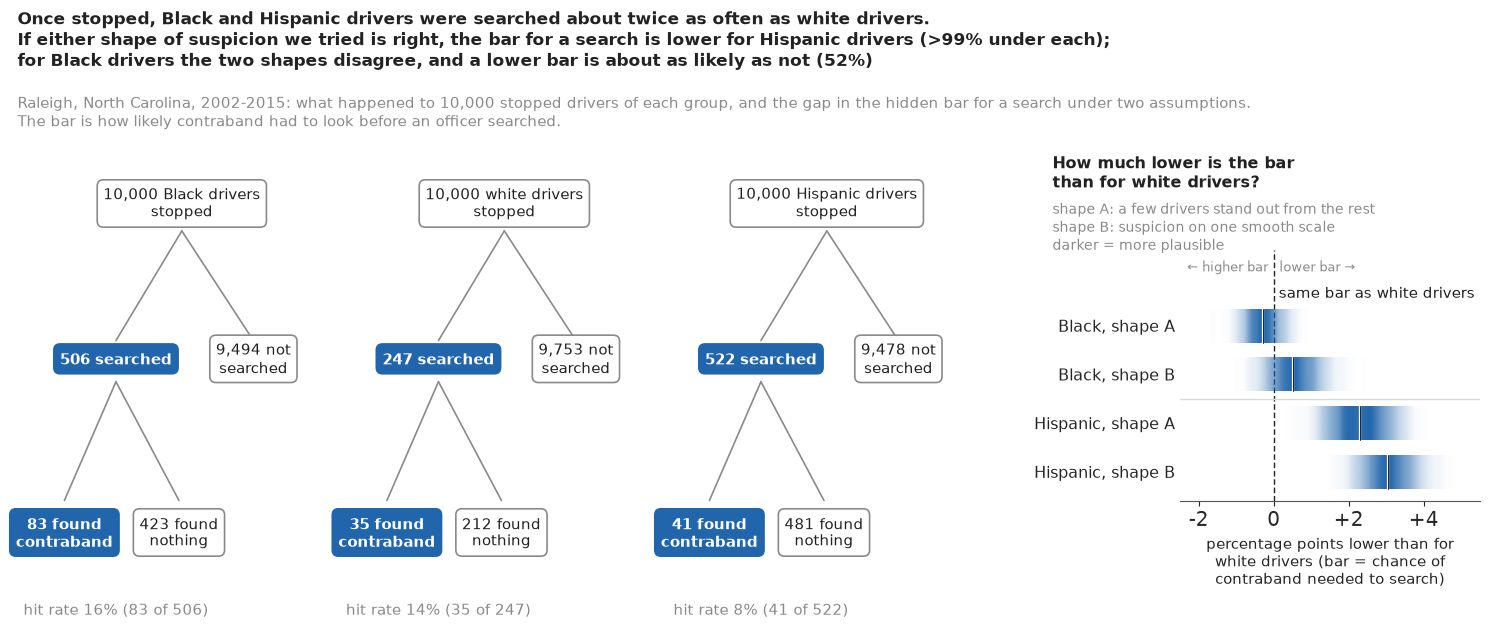

In [2]:
HOW_SURE = display(Markdown("**How sure are we.** *Filled in from the pooled posterior in part G.*"),
                   display_id=True)
HEADLINE = display(Markdown("*The headline figure is drawn in part G from the fits below and "
                            "appears here once the notebook has run.*"), display_id=True)

## The setting

US police make tens of millions of traffic stops a year, and in a few percent of them the officer
searches the driver or the car. Whether those searches treat drivers of different races alike is
one of the most argued questions in American public life. Search *rates* do not settle it: if Black drivers are searched twice as often as
white drivers, that may be because officers hold them to a lower standard of suspicion, or because
more of the stopped Black drivers show the signs officers look for, or both.

Becker (1957) suggested looking at outcomes instead. If officers search whenever the chance of
finding contraband is high enough, and the bar for "high enough" is the same for everyone, then
the searches of the *marginal* driver - the one just over the bar - succeed equally often in
every group. A group searched on weaker evidence would show a lower success rate. Knowles,
Persico & Todd (2001) turned this into the **outcome test**, or hit-rate test: compare the
share of searches that find contraband across groups. It is simple, it uses data police
departments already publish, and it is often reported as if it settled the matter.

The catch, which Ayres (2002) and Simoiu, Corbett-Davies & Goel (2017) put at the centre, is that
a hit rate is an average over *everyone* searched, not the success rate at the margin. Two groups
can face exactly the same bar and still have very different hit rates, if the spread of
suspicion above the bar differs between them. That is **infra-marginality**, and part B shows it
with two invented groups. Simoiu et al.'s answer is the **threshold test**: write down a
generative model in which each stopped driver has a latent risk drawn from a group-specific
distribution, officers search when the risk exceeds a group-specific threshold, and both the
search rate and the hit rate follow from those two hidden objects. Fitted jointly to many units
(police departments, officers, years), the model places the thresholds, and the comparison of
thresholds is the test. Pierson, Corbett-Davies & Goel (2018) gave a faster version with a
closed-form likelihood. Pierson et al. (2020) collected some 100 million stops in the Stanford
Open Policing Project, including the Raleigh file used here, and applied the threshold test to
the agencies that record search outcomes. Gelman, Fagan & Kiss (2007) showed the same multilevel
thinking on New York's stop-and-frisk data.

The threshold test is pure Bayesian modelling: the estimand is a latent cut-off, identified only
by the structure we write down. That makes it a good lesson and a dangerous one, and the lesson is
not the one we set out to find.
The test gives a firm answer for Hispanic drivers. For Black drivers its
answer flips with an assumption about the *shape* of suspicion that these data cannot check, and
we will show why that matters by fitting the model to invented worlds in which the bar is
equal by construction.

Two limits frame everything below. The test compares searches *given a stop*: if stops themselves
are biased, the stopped populations differ in ways the model cannot see (Knox, Lowe & Mummolo
2020). And a "bar" here is a statement about behaviour on average, not about any one officer's
intent.

| part | question | tool |
|---|---|---|
| A | What do the records show? | search and hit rates by race, basis and year; the outcome test |
| B | Can the same bar give different hit rates? | two invented groups, one bar (NumPy) |
| C | Can one city's two rates place its bar? | the discriminant risk family; a ridge of exact solutions |
| D | Where are officers' bars? | a hierarchical threshold model over 214 officers and a pooled unit; diagnostics, checks, a second prior, gaps |
| E | Did the bars move over time? | 14 years as units; a graded fan of the yearly gap |
| F | What would change our mind? | a second risk shape; LOO; placebo worlds with equal bars; consent searches |
| G | How do we explain it to everyone? | frequency trees with a gap panel, a "bar" ladder, a value-suppressing beeswarm, calibrated words |

## A · What the records show

The build script turns the 856,400 stop records into counts: for every unit (the city, each
year, each officer) and each driver race, the number of stops, searches and searches that found
contraband ("hits"), with the searches split by their recorded basis. Other and unknown races
(8,644 stops) are dropped.

In [3]:
data.describe("e110_raleigh_units")
RAW = data.load("e110_raleigh_units")
city = RAW[RAW.level == "city"].set_index("race")
tbl = city[["stops", "searches", "hits"]].copy()
tbl["searched per 1,000 stops"] = (1000 * tbl.searches / tbl.stops).round(1)
tbl["hit rate %"] = (100 * tbl.hits / tbl.searches).round(1)
tbl.index = [NAME[r] for r in tbl.index]
print(tbl.to_string())
rate_ = tbl["searched per 1,000 stops"]
print(f"\nBlack / white search-rate ratio {rate_['Black'] / rate_['white']:.2f}, "
      f"Hispanic / white {rate_['Hispanic'] / rate_['white']:.2f}")

e110_raleigh_units: One row per unit and driver race (6,452 rows): level ('city', 'year' or 'officer'), unit ('Raleigh', the year 2002-2015, or a 10-character officer_id_hash), race (black, white, hispanic, asian; 'other' and 'unknown', 8,644 stops, dropped), stops, searches, hits (searches that found contraband), and the searches/hits split by search basis: searches_consent / hits_consent, searches_pc / hits_pc (probable cause), searches_other / hits_other (protective frisks, incident to arrest, ...); 528 searches with no recorded basis count only in the totals. City totals: Black 383,628 stops / 19,395 searches / 3,198 hits; white 361,319 / 8,926 / 1,270; Hispanic 87,460 / 4,568 / 359; Asian 15,349 / 225 / 30. 1,598 officers (457 with 20 or more searches); officer x race rows with no stops are written as zeros.
  source: Stanford Open Policing Project (Pierson et al. 2020, Nature Human Behaviour), Raleigh, North Carolina city file, standardised release of 2020-04-01: 856,400 vehicula

Black and white drivers were stopped in similar numbers, about 380,000 and 360,000 times, and
Hispanic drivers about 87,000 times. Black and Hispanic drivers were searched about twice as
often per stop as white drivers (about 51 and 52 per 1,000 against 25). The hit rates go the other
way for Black drivers: 16.5% of searches of Black drivers found contraband against 14.2% for white
drivers. Hispanic drivers have both a high search rate and by far the lowest hit rate, 7.9%.
Asian and Pacific Islander drivers were rarely searched (225 searches in 14 years); we keep them
only in the year model of part E.

### The outcome test

Read the way Knowles, Persico & Todd read it, these numbers say: no sign that Black drivers are
searched on weaker evidence (their searches succeed *more* often), and a clear sign that Hispanic
drivers are (their searches succeed half as often). With 19,000 and 9,000 searches the hit rates
are measured to about half a point, so the conclusion looks decisive. Before we question the
logic, two features of the record matter later.

### Search basis and time

                                     Black  white  Hispanic
consent searches per 1,000 stops      17.5    6.5      12.1
consent hit rate %                    10.6   13.4       6.9
probable-cause searches per 1,000     14.7    4.8       6.9
probable-cause hit rate %             31.3   28.4      19.5
other searches per 1,000              17.3   13.2      32.6
other hit rate %                      10.1    9.5       5.8
hit rate without consent searches %   19.6   14.5       8.2


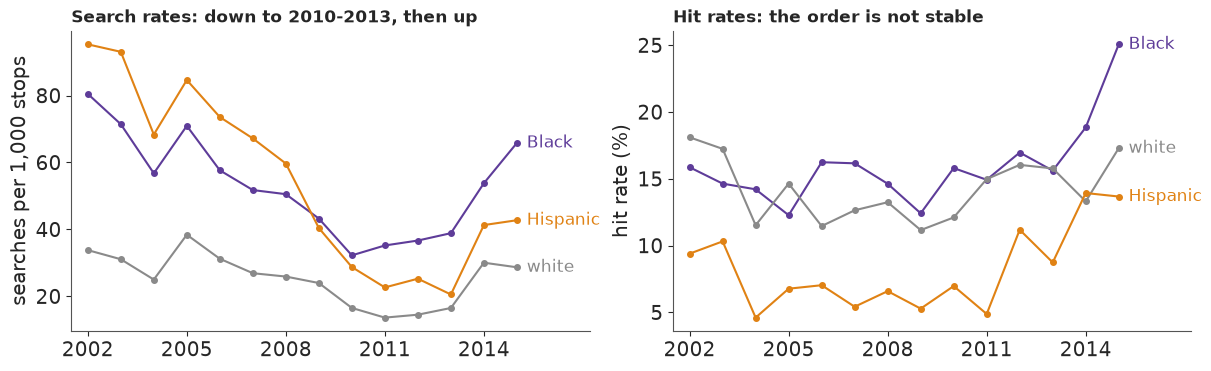

In [4]:
basis = pd.DataFrame({
    NAME[r]: {
        "consent searches per 1,000 stops": 1000 * city.searches_consent[r] / city.stops[r],
        "consent hit rate %": 100 * city.hits_consent[r] / city.searches_consent[r],
        "probable-cause searches per 1,000": 1000 * city.searches_pc[r] / city.stops[r],
        "probable-cause hit rate %": 100 * city.hits_pc[r] / city.searches_pc[r],
        "other searches per 1,000": 1000 * city.searches_other[r] / city.stops[r],
        "other hit rate %": 100 * city.hits_other[r] / city.searches_other[r],
        "hit rate without consent searches %": 100 * (city.hits[r] - city.hits_consent[r])
        / (city.searches[r] - city.searches_consent[r]),
    } for r in RACES}).round(1)
print(basis.to_string())

yr = RAW[(RAW.level == "year") & RAW.race.isin(RACES)].copy()
yr["year"] = yr.unit.astype(int)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
for r in RACES:
    g = yr[yr.race == r].sort_values("year")
    axs[0].plot(g.year, 1000 * g.searches / g.stops, "o-", color=RCOL[r], ms=4)
    axs[1].plot(g.year, 100 * g.hits / g.searches, "o-", color=RCOL[r], ms=4)
    axs[0].text(2015.3, 1000 * g.searches.iloc[-1] / g.stops.iloc[-1], NAME[r], color=RCOL[r], va="center")
    axs[1].text(2015.3, 100 * g.hits.iloc[-1] / g.searches.iloc[-1], NAME[r], color=RCOL[r], va="center")
axs[0].set_ylabel("searches per 1,000 stops")
axs[1].set_ylabel("hit rate (%)")
for ax in axs:
    ax.set_xlim(2001.5, 2017.2)
    ax.set_xticks(range(2002, 2016, 3))
axs[0].set_title("Search rates: down to 2010-2013, then up", loc="left", fontsize=12)
axs[1].set_title("Hit rates: the order is not stable", loc="left", fontsize=12);

A third of the searches of Black drivers were by **consent**: the officer asked and the driver
agreed, with no probable cause needed. Black drivers were asked about 2.7 times as often as white
drivers (17.5 against 6.5 per 1,000 stops), and those searches found less (10.6% against 13.4%).
Leave consent searches out and the Black hit rate rises to 19.6% while the white one barely moves
(14.5%). Whatever the threshold test says, it will be partly a statement about who gets asked.

Over time, search rates fell to a low between 2010 and 2013 and then rose again; the Hispanic rate
fell most, from about 9.5% to 2-4%. Hit rates wander by several points from year to year, and the
Black hit rate jumps to about 25% in 2015. The records show no break (no missing years, normal stop
counts in 2015), but part E treats each year as its own unit rather than assume a smooth trend.

## B · One bar, two hit rates

Why can't the hit rates settle the question? Take two invented groups of stopped drivers. In both,
5% carry contraband. The officer sees a signal - nervousness, a smell, what is on the seat - that
is on average higher for carriers. Write it as $x \sim N(\delta, 1)$ for carriers and
$x \sim N(0, 1)$ for everyone else. After seeing $x$, the officer's honest estimate of the
chance that the driver carries something is, by Bayes' rule,

$$r(x) = \operatorname{logit}^{-1}\!\Big(\operatorname{logit}\phi + \delta x - \tfrac{\delta^2}{2}\Big),$$

with $\phi$ the share of carriers. The separation $\delta$ says how readable the group is: with a
large $\delta$ the signal sorts carriers from non-carriers well, and risks pile up near 0 and
near 1; with a small one everyone looks much alike. In group 1 the signal is easy to read
($\delta = 2.5$), in group 2 hard ($\delta = 1.5$). The officer searches whenever $r(x)$ exceeds
a bar $t$. The search rate and the hit rate are then

$$S = \phi\,Q(x^* - \delta) + (1 - \phi)\,Q(x^*),\qquad H = \frac{\phi\,Q(x^* - \delta)}{S},
\qquad x^* = \frac{\operatorname{logit} t - \operatorname{logit}\phi}{\delta} + \frac{\delta}{2},$$

where $Q$ is the normal upper-tail probability and $x^*$ is the signal at which the risk equals
the bar. Below, both groups first face the same bar of 10%; then group 2 faces a *higher* bar of
15% and group 1 a *lower* one of 7%.

Same bar for both      group 1 (easy to read)   bar 10%: searched  99.1 per 1,000, hit rate 41.8%   (simulated:  99.2, 41.7%)
Same bar for both      group 2 (hard to read)   bar 10%: searched 130.7 per 1,000, hit rate 22.9%   (simulated: 130.6, 23.0%)
Lower bar for group 1  group 1 (easy to read)   bar 7%: searched 121.0 per 1,000, hit rate 35.8%   (simulated: 121.0, 35.7%)
Lower bar for group 1  group 2 (hard to read)   bar 15%: searched  80.7 per 1,000, hit rate 29.6%   (simulated:  81.3, 29.6%)


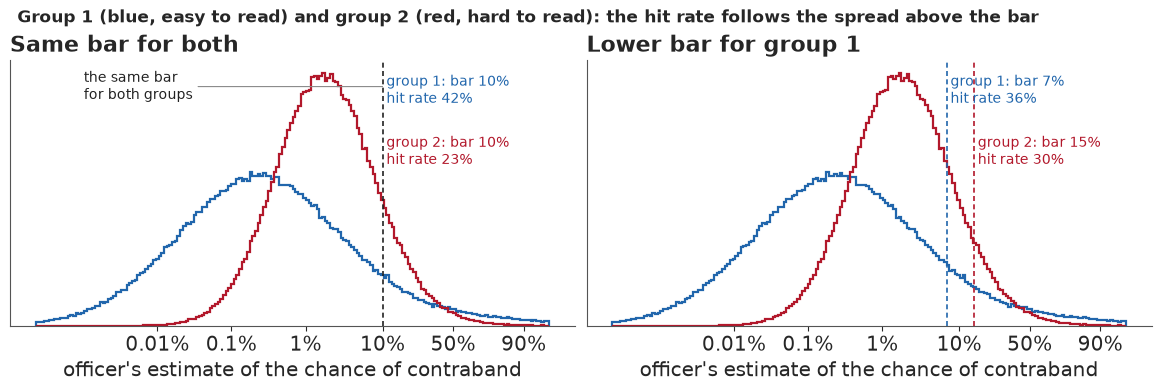

In [5]:
def rates_np(phi, delta, t):
    """Search rate S and hit rate H of the discriminant risk family (NumPy)."""
    xs = (logit(t) - logit(phi)) / delta + delta / 2
    a = phi * norm.sf(xs - delta)
    S = a + (1 - phi) * norm.sf(xs)
    return S, a / S


def risk_draws(phi, delta, n, g):
    """Risk r(x) of n stopped drivers from the discriminant family."""
    carrier = g.random(n) < phi
    x = g.normal(size=n) + delta * carrier
    return expit(logit(phi) + delta * x - delta**2 / 2)


TOY = {"group 1 (easy to read)": (0.05, 2.5), "group 2 (hard to read)": (0.05, 1.5)}
TOY2 = "#b2182b"   # group 2's colour: kept apart from the race colours used later
SCEN = {"Same bar for both": {"group 1 (easy to read)": 0.10, "group 2 (hard to read)": 0.10},
        "Lower bar for group 1": {"group 1 (easy to read)": 0.07, "group 2 (hard to read)": 0.15}}
g_toy = np.random.default_rng(1)
risk = {k: risk_draws(*v, 400_000, g_toy) for k, v in TOY.items()}
for sc, bars in SCEN.items():
    for k, (phi, dl) in TOY.items():
        S, Hr = rates_np(phi, dl, bars[k])
        Smc = (risk[k] > bars[k]).mean()
        Hmc = risk[k][risk[k] > bars[k]].mean()
        print(f"{sc:22s} {k:24s} bar {bars[k]:.0%}: searched {1000 * S:5.1f} per 1,000, hit rate {Hr:.1%}"
              f"   (simulated: {1000 * Smc:5.1f}, {Hmc:.1%})")

fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.8), sharey=True)
bins = np.linspace(-13, 3, 193)
for ax, (sc, bars) in zip(axs, SCEN.items()):
    shared = len(set(bars.values())) == 1
    if shared:   # one bar for both groups: one line, labelled as such in a clear corner
        xb = logit(bars[next(iter(TOY))])
        ax.axvline(xb, color=INK, lw=1.2, ls=(0, (3, 2)))
        ax.annotate("the same bar\nfor both groups", xy=(xb, 0.9), xytext=(-11.5, 0.9), color=INK, fontsize=10,
                    va="center", xycoords=ax.get_xaxis_transform(), textcoords=ax.get_xaxis_transform(),
                    arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8, shrinkA=2, shrinkB=0))
    for k, col in zip(TOY, [HI, TOY2]):
        lr = logit(np.clip(risk[k], 1e-7, 1 - 1e-7))
        h, e = np.histogram(lr, bins=bins, density=True)
        ax.stairs(h, e, color=col, lw=1.6)
        if not shared:
            ax.axvline(logit(bars[k]), color=col, lw=1.2, ls=(0, (3, 2)))
        S, Hr = rates_np(*TOY[k], bars[k])
        ax.text(logit(bars[k]) + 0.12, 0.95 if col == HI else 0.72, f"{k.split(' (')[0]}: bar {bars[k]:.0%}\n"
                f"hit rate {Hr:.0%}", color=col, fontsize=10, va="top", transform=ax.get_xaxis_transform())
    ticks = np.array([0.0001, 0.001, 0.01, 0.1, 0.5, 0.9])
    ax.set_xticks(logit(ticks), [f"{100 * v:g}%" for v in ticks])
    ax.set_xlabel("officer's estimate of the chance of contraband")
    ax.set_title(sc, loc="left")
axs[0].set_yticks([])
fig.suptitle("Group 1 (blue, easy to read) and group 2 (red, hard to read): the hit rate follows "
             "the spread above the bar", x=0.01, ha="left", fontsize=12);

The closed forms agree with 400,000 simulated drivers, which is the first check on the formulas
we will put inside PyMC. With the *same* 10% bar for both groups, group 1's searches find
contraband 42% of the time and group 2's only 23%. An outcome test would conclude that officers
search group 2 on weaker evidence, and it would be wrong: the bar is identical. Group 1's searched
drivers are mostly obvious cases far above the bar, while group 2's sit just over it. In the
second panel group 1 faces a bar of 7% and group 2 one of 15% - group 1 is searched on half the
evidence - yet group 1's hit rate (36%) is *higher* than group 2's (30%). The outcome test would
clear exactly the discrimination it was designed to find. The hit rate is an average over
everyone above the bar, and the bar is the edge of that set: two different objects.

## C · Two rates, three unknowns

### One city cannot place its bar

The threshold test replaces the outcome test with the model of part B, run backwards: from the
observed search rate and hit rate, find the bar. The family above, which Pierson, Corbett-Davies
& Goel (2018) call the **discriminant** family, has three unknowns per group ($\phi$, $\delta$,
$t$) and each group gives two numbers. So for any bar we choose, we can look for a share of
carriers and a separation that reproduce Raleigh's two rates exactly. The cell below does that
with a root finder for a grid of bars from 0.2% up to the group's hit rate.

Black     (hit rate 16.5%): exact solutions for bars from 0.2% to 16.4%; share carrying 0.8%-16.1%, separation 0.01-4.14; no solution for 0 of 40 bars
white     (hit rate 14.2%): exact solutions for bars from 0.2% to 14.2%; share carrying 0.4%-13.8%, separation 0.02-4.32; no solution for 0 of 40 bars
Hispanic  (hit rate 7.9%): exact solutions for bars from 0.2% to 7.8%; share carrying 0.4%-7.7%, separation 0.01-3.72; no solution for 0 of 40 bars


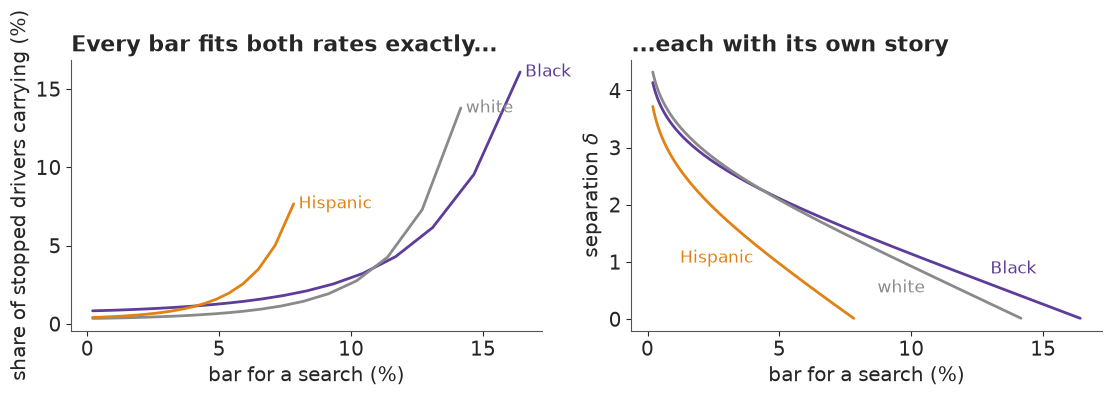

In [6]:
def solve_ridge(S0, H0, bars):
    """For each bar t, the (phi, delta) of the discriminant family that give search rate S0 and hit rate H0."""
    out, guess = [], np.array([logit(H0 * S0 * 1.5), 0.0])
    for t in bars:
        f = lambda v: np.array(rates_np(expit(v[0]), np.exp(v[1]), t)) / [S0, H0] - 1
        best = None
        for g0 in [guess, (-3, 0), (-4, 1), (-2, -0.5), (-5, 1.5), (-1.5, -1)]:
            v, info, ier, _ = fsolve(f, g0, full_output=True)
            if ier == 1 and np.abs(f(v)).max() < 1e-8:
                best = v
                break
        out.append((t, np.nan, np.nan) if best is None else (t, expit(best[0]), np.exp(best[1])))
        guess = best if best is not None else guess
    return pd.DataFrame(out, columns=["bar", "share carrying", "separation"])


RIDGE = {}
for r in RACES:
    S0, H0 = city.searches[r] / city.stops[r], city.hits[r] / city.searches[r]
    RIDGE[r] = solve_ridge(S0, H0, np.geomspace(0.002, 0.995 * H0, 40))
    ok = RIDGE[r].dropna()
    print(f"{NAME[r]:9s} (hit rate {H0:.1%}): exact solutions for bars from {ok.bar.min():.1%} to {ok.bar.max():.1%}; "
          f"share carrying {ok['share carrying'].min():.1%}-{ok['share carrying'].max():.1%}, "
          f"separation {ok.separation.min():.2f}-{ok.separation.max():.2f}; no solution for "
          f"{int(RIDGE[r]['share carrying'].isna().sum())} of 40 bars")

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for r in RACES:
    ok = RIDGE[r].dropna()
    axs[0].plot(100 * ok.bar, 100 * ok["share carrying"], color=RCOL[r], lw=2)
    axs[1].plot(100 * ok.bar, ok.separation, color=RCOL[r], lw=2)
    axs[0].text(100 * ok.bar.iloc[-1], 100 * ok["share carrying"].iloc[-1], " " + NAME[r], color=RCOL[r], va="center")
    xq, dy, va_, ha_ = {"black": (13, 0.12, "bottom", "left"), "white": (10.5, -0.12, "top", "right"),
                        "hispanic": (4, -0.12, "top", "right")}[r]
    axs[1].text(xq, np.interp(xq, 100 * ok.bar, ok.separation) + dy, NAME[r], color=RCOL[r], va=va_, ha=ha_)
for ax in axs:
    ax.set_xlabel("bar for a search (%)")
axs[0].set_ylabel("share of stopped drivers carrying (%)")
axs[1].set_ylabel(r"separation $\delta$")
axs[0].set_title("Every bar fits both rates exactly...", loc="left")
axs[1].set_title("...each with its own story", loc="left");

Every bar from 0.2% up to just under the group's own hit rate reproduces Raleigh's search and
hit rates exactly, each with its own story. A low bar goes with a small share of carriers who are
easy to tell apart; a bar near the hit rate needs many carriers and a signal that barely separates
them. The only hard fact one unit gives is that the bar lies below the hit rate, which is what
part B showed: the hit rate averages over everyone above the bar. Fitting a model to the city
totals alone would return the prior along this ridge. Simoiu et al. (2017) fitted many
departments at once for exactly this reason, and we use officers.

### What many units add

Suppose officer $d$'s drivers of race $r$ follow the same family with

$$\operatorname{logit}\phi_{dr} = a_r + \sigma_a z^a_d,\qquad \log\delta_{dr} = b_r + \sigma_b z^b_d,
\qquad \operatorname{logit} t_{dr} = c_r + \sigma_c z^c_d + \sigma_e z^e_{dr},$$

with every $z \sim N(0,1)$. An officer's effects on the share of carriers ($z^a_d$: where they
patrol, what they stop for), on readability ($z^b_d$) and on their general bar ($z^c_d$) are
shared across races; only the bar gets an extra officer-by-race deviation $z^e_{dr}$. With the
race effects $a_r$, $b_r$, $c_r$ common to all officers, the ridge is cut: an officer whose drivers
are searched often but rarely found carrying must have either many hard-to-read drivers or a low
bar, and the other officers' drivers of the same race tell us which. The identification comes
entirely from this additive structure, and part F asks how much it leans on the shape of the risk
family.

## D · The bars of 214 officers and the rest

### The table

The hierarchical model works on officers. 1,598 officers appear in the file, most with only a
handful of searches. We keep the 214 officers with at least 50 searches of Black, white and
Hispanic drivers (63% of those searches) as units of their own and pool the other 1,384 into one
"other officers" unit. A lower cut of 20 searches would name 454 officers counting searches of
Black, white and Hispanic drivers (457 with Asian drivers included, the count printed above), at
two to three times the cost per fit. Two cautions come with this choice. Officers become named
units by searching often, which depends on their bar, so they are selected on the outcome. And
the pooled unit mixes many officers' risk distributions and bars: its fitted bar is a summary the
model needs, not any real officer's bar.

In [7]:
POOL = "other officers"


def officer_table(min_searches=50):
    """Officer x race counts; officers below min_searches pooled into one unit."""
    o = RAW[(RAW.level == "officer") & RAW.race.isin(RACES)].copy()
    tot = o.groupby("unit").searches.sum()
    big = sorted(tot.index[tot >= min_searches])
    o["u"] = np.where(o.unit.isin(big), o.unit, POOL)
    o = o.groupby(["u", "race"], sort=False)[["stops", "searches", "hits"]].sum().reset_index()
    return o[o.stops > 0].reset_index(drop=True), list(big) + [POOL]


OFF, UNITS = officer_table(50)
W_ALL = OFF.groupby("u").stops.sum().reindex(UNITS).to_numpy()
W_ALL = W_ALL / W_ALL.sum()                       # each unit's share of all stops (same for every race)
W_OFF = np.r_[W_ALL[:-1], 0.0] / W_ALL[:-1].sum()  # the 214 named officers only
per = OFF[OFF.u != POOL].groupby("u")[["stops", "searches"]].sum()
print(f"{len(UNITS) - 1} officers + 1 pooled unit, {len(OFF)} officer x race cells")
print(f"searches per officer: median {per.searches.median():.0f}, range {per.searches.min()}-{per.searches.max()}; "
      f"stops per officer: median {per.stops.median():.0f}")
print(f"share of all stops made by the pooled unit: {W_ALL[-1]:.0%}")
print("searches by race:", OFF.groupby("race").searches.sum().to_dict())

214 officers + 1 pooled unit, 645 officer x race cells
searches per officer: median 78, range 50-410; stops per officer: median 1078
share of all stops made by the pooled unit: 60%
searches by race: {'black': 19395, 'hispanic': 4568, 'white': 8926}


The 214 named officers search a median of about 80 times each over their careers in the file, and
the 1,384 officers in the pooled unit, though they make only about a third of the searches,
together make 60% of the stops. That matters for what "the
city's bar" means. We summarise each race's bar as the **stop-weighted average** of the units'
bars, $\bar t_r = \sum_d w_d\, t_{dr}$, with $w_d$ the unit's share of all stops, the *same*
weights for every race, so that a gap between races is not a difference in who stops whom. With
60% of the weight on a unit that lumps more than a thousand officers together, we also report
the average over the 214 named officers alone.

### The model in PyMC

The likelihood is two binomials per cell, searches out of stops and hits out of searches, with
the probabilities from the closed forms of part B. We compute them on the log scale: each of the
four joint events (carrier or not, searched or not) is a log normal tail, combined with
`logaddexp`, so nothing underflows when an officer's search rate is a fraction of a percent.
Priors: $a_r \sim N(-2, 1)$ (a share of carriers between about 2% and 50%), $b_r \sim N(0.5, 0.5)$
(separations from about 0.6 to 4), $c_r \sim N(-1.5, 1)$ (bars from about 3% to 60%), half-normal
officer scales with sd 0.5 and 0.3 for the officer-by-race deviation. The second family, built by
the same function, is part F's; the prior predictive check below covers both.

In [8]:
SQ2 = np.sqrt(2.0)


def log_q(z):
    """log of the normal upper tail, log(1 - Phi(z))."""
    return pt.log(0.5 * pt.erfc(z / SQ2))


def rates_A(logit_phi, log_delta, logit_t):
    """Discriminant family (Pierson et al. 2018): logit search rate and logit hit rate, in closed form."""
    delta = pt.exp(log_delta)
    xs = (logit_t - logit_phi) / delta + delta / 2
    lphi, l1phi = -pt.softplus(-logit_phi), -pt.softplus(logit_phi)   # log phi, log(1 - phi)
    hit = lphi + log_q(xs - delta)          # carrier, searched
    miss = l1phi + log_q(xs)                # not a carrier, searched
    log_s = pt.logaddexp(hit, miss)
    log_not = pt.logaddexp(lphi + log_q(delta - xs), l1phi + log_q(-xs))
    return log_s - log_not, hit - miss


GL_X, GL_W = np.polynomial.legendre.leggauss(16)
GL_X, GL_W = (GL_X + 1) / 2 * 9.0, GL_W / 2 * 9.0   # 16 nodes on [0, 9] sd above the cut-off


def rates_B(m, log_s, logit_t):
    """Logit-normal family: logit risk ~ N(m, s). H = E[risk | searched] by Gauss-Legendre quadrature."""
    s = pt.exp(log_s)
    zs = (logit_t - m) / s
    log_S = log_q(zs)
    z = zs[..., None] + GL_X
    lw = -0.5 * z**2 - 0.5 * np.log(2 * np.pi) + np.log(GL_W) - log_S[..., None]
    H = pt.clip(pt.sum(pt.sigmoid(m[..., None] + s[..., None] * z) * pt.exp(lw), axis=-1), 1e-9, 1 - 1e-9)
    return log_S - log_q(-zs), pt.log(H) - pt.log1p(-H)


def threshold_model(tab, units, races, family="A", a0=None, c0=-1.5):
    ui = pd.Index(units).get_indexer(tab.u)
    ri = pd.Index(races).get_indexer(tab.race)
    assert (ui >= 0).all() and (ri >= 0).all()
    loc = {"A": (-2.0, 0.5), "B": (-3.0, 0.0)}[family]
    loc = (loc[0] if a0 is None else a0, loc[1])
    with pm.Model(coords={"unit": units, "race": races, "cell": np.arange(len(tab))}) as m:
        a_r = pm.Normal("a_r", loc[0], 1.0, dims="race")      # A: logit share carrying; B: mean logit risk
        b_r = pm.Normal("b_r", loc[1], 0.5, dims="race")      # A: log separation;       B: log sd of logit risk
        c_r = pm.Normal("c_r", c0, 1.0, dims="race")          # logit bar
        s_a, s_b, s_c = (pm.HalfNormal(v, 0.5) for v in ("s_a", "s_b", "s_c"))
        s_e = pm.HalfNormal("s_e", 0.3)
        za, zb, zc = (pm.Normal(v, 0.0, 1.0, dims="unit") for v in ("za", "zb", "zc"))
        ze = pm.Normal("ze", 0.0, 1.0, dims=("unit", "race"))
        lt = c_r[None, :] + s_c * zc[:, None] + s_e * ze
        pm.Deterministic("t", pm.math.sigmoid(lt), dims=("unit", "race"))
        A = a_r[ri] + s_a * za[ui]
        B = b_r[ri] + s_b * zb[ui]
        ls, lh = (rates_A if family == "A" else rates_B)(A, B, lt[ui, ri])
        pm.Binomial("searches", n=tab.stops.to_numpy(), logit_p=ls, observed=tab.searches.to_numpy(), dims="cell")
        pm.Binomial("hits", n=tab.searches.to_numpy(), logit_p=lh, observed=tab.hits.to_numpy(), dims="cell")
    return m


def prior_check(label, family="A", **prior):
    m_prior = threshold_model(OFF, UNITS, RACES, family, **prior)
    with m_prior:
        pri = pm.sample_prior_predictive(500, random_seed=RANDOM_SEED)
    ps_ = pri.prior_predictive["searches"].to_numpy().reshape(500, -1)
    ph_ = pri.prior_predictive["hits"].to_numpy().reshape(500, -1)
    tb_ = pri.prior["t"].to_numpy().reshape(500, len(UNITS), 3)
    for j, r in enumerate(RACES):
        k = (OFF.race == r).to_numpy()
        sr = ps_[:, k].sum(1) / OFF.stops[k].sum()
        hr = ph_[:, k].sum(1) / OFF.searches[k].sum()      # hits are drawn out of the OBSERVED searches
        print(f"{label}, {NAME[r]:8s}: search rate {np.quantile(sr, .055):.1%}-{np.quantile(sr, .945):.1%}, "
              f"hit rate {np.quantile(hr, .055):.0%}-{np.quantile(hr, .945):.0%}, average bar "
              f"{np.quantile(tb_[:, :, j] @ W_ALL, .055):.0%}-{np.quantile(tb_[:, :, j] @ W_ALL, .945):.0%}")


# fewer carriers (A) or a lower mean risk (B), and a lower bar: parts D and F refit with these
LOW_PRIOR = {"A": dict(a0=-3.5, c0=-3.0), "B": dict(a0=-4.5, c0=-3.0)}
for fam in ("A", "B"):
    prior_check(f"shape {fam}, default prior", fam)
    prior_check(f"shape {fam}, lower prior  ", fam, **LOW_PRIOR[fam])

shape A, default prior, Black   : search rate 1.7%-75.9%, hit rate 21%-88%, average bar 5%-51%
shape A, default prior, white   : search rate 2.4%-80.4%, hit rate 20%-88%, average bar 4%-52%
shape A, default prior, Hispanic: search rate 1.2%-81.5%, hit rate 21%-86%, average bar 4%-54%


shape A, lower prior  , Black   : search rate 0.9%-70.4%, hit rate 6%-69%, average bar 1%-19%
shape A, lower prior  , white   : search rate 1.4%-74.1%, hit rate 6%-66%, average bar 1%-20%
shape A, lower prior  , Hispanic: search rate 0.6%-78.2%, hit rate 6%-66%, average bar 1%-22%


shape B, default prior, Black   : search rate 0.2%-73.7%, hit rate 12%-64%, average bar 5%-51%
shape B, default prior, white   : search rate 0.2%-77.0%, hit rate 13%-64%, average bar 4%-52%
shape B, default prior, Hispanic: search rate 0.1%-79.2%, hit rate 12%-64%, average bar 4%-54%


shape B, lower prior  , Black   : search rate 0.2%-73.7%, hit rate 3%-36%, average bar 1%-19%
shape B, lower prior  , white   : search rate 0.2%-77.0%, hit rate 3%-37%, average bar 1%-20%
shape B, lower prior  , Hispanic: search rate 0.1%-79.2%, hit rate 3%-35%, average bar 1%-22%


On search rates and bars the default priors rule out nothing a reader could believe. On hit rates
they fail: their 89% range lies above Raleigh's 8-17% for shape A, and its lower end sits at
about 12% for shape B, because they put too many carriers among the stopped drivers and the bar
too high. The **lower priors** ($a_r \sim N(-3.5, 1)$ for A, $N(-4.5, 1)$ for B, and
$c_r \sim N(-3, 1)$ for both) cover Raleigh's hit rates. We still fit with the default priors,
for a reason the next section shows: the level of the bar sits on a ridge, and the lower prior
makes that ridge much harder to sample for shape A. With 33,000 searches the data override either
prior for the rates, and we refit both shapes with the lower priors to see what moves. All three
races get the same priors.

### Fitting, and a ridge that does not go away

One helper fits a model with nutpie, prints the diagnostics that matter here, keeps only the
officer-by-race bars, and runs a posterior predictive check and PSIS-LOO when asked. We use 600
warm-up steps and 600 draws per chain with `target_accept=0.9`; longer warm-up did not help, for a
reason the output shows.

In [9]:
def rhat_ess(arr):
    """r_hat and bulk ESS of a (chain, draw, ...) NumPy array of derived draws."""
    ds = xr.Dataset({"x": (("chain", "draw") + tuple(f"d{i}" for i in range(arr.ndim - 2)), arr)})
    return az.rhat(ds)["x"].to_numpy(), az.ess(ds)["x"].to_numpy()


def avg_bars(res, w):
    return np.einsum("cdur,u->cdr", res["t"], w)          # (chain, draw, race)


def gap(res, w, other, ref="white"):
    """Bar for white drivers minus bar for `other` drivers, in percentage points, (chain, draw)."""
    T = avg_bars(res, w)
    return 100 * (T[..., res["races"].index(ref)] - T[..., res["races"].index(other)])


def fit(tab, units, races, family, label, *, draws=600, tune=600, w=None, ppc=True, loo=False, seed=RANDOM_SEED,
        prior=None):
    m = threshold_model(tab, units, races, family, **(prior or {}))
    t0 = time.time()
    idata = pm.sample(draws=draws, tune=tune, chains=4, target_accept=0.9, random_seed=seed,
                      progressbar=False, model=m)
    sec = time.time() - t0
    post, st = idata.posterior, idata.sample_stats
    res = dict(label=label, sec=sec, races=races, units=units, div=int(st["diverging"].sum()),
               t=post["t"].transpose("chain", "draw", "unit", "race").to_numpy())
    w = W_ALL if w is None else w
    rh_mean = max(float(az.rhat(idata, var_names=[v])[v].max()) for v in ("a_r", "b_r", "c_r"))
    ess_mean = min(float(az.ess(idata, var_names=[v])[v].min()) for v in ("a_r", "b_r", "c_r"))
    rh_T, _ = rhat_ess(avg_bars(res, w))
    gaps = np.stack([gap(res, w, r) for r in races if r != "white"], -1)
    rh_g, ess_g = rhat_ess(gaps)
    rh_t, _ = rhat_ess(res["t"])
    print(f"{label}: {sec:.0f} s (warm-up {post.attrs.get('tuning_steps')}), divergences {res['div']}, tree depth "
          f"mean {float(st['depth'].mean()):.1f} max {int(st['depth'].max())}")
    print(f"   r_hat: race-level means up to {rh_mean:.3f} (bulk ESS from {ess_mean:.0f}); average bars up to "
          f"{rh_T.max():.3f}; gaps up to {rh_g.max():.3f} (ESS from {ess_g.min():.0f}); unit bars up to {rh_t.max():.3f}")
    res["scales"] = {v: np.quantile(post[v].to_numpy(), [0.055, 0.5, 0.945]) for v in ("s_a", "s_b", "s_c", "s_e")}
    print("   scales (median, 89%): " + ", ".join(f"{v} {q[1]:.2f} ({q[0]:.2f}-{q[2]:.2f})"
                                                for v, q in res["scales"].items()))
    if ppc:
        pp = pm.sample_posterior_predictive(idata.isel(draw=slice(None, None, 10)), model=m, random_seed=1,
                                            progressbar=False).posterior_predictive
        ys = pp["searches"].to_numpy().reshape(-1, len(tab))
        yh = pp["hits"].to_numpy().reshape(-1, len(tab))
        for r in races:
            k = (tab.race == r).to_numpy()
            n = tab.stops[k].sum()
            print(f"   check {NAME[r]:9s}: search rate {tab.searches[k].sum() / n:.2%} observed, "
                  f"{np.quantile(ys[:, k].sum(1) / n, .055):.2%}-{np.quantile(ys[:, k].sum(1) / n, .945):.2%} replicated; "
                  f"hits {tab.hits[k].sum():,} observed, {np.quantile(yh[:, k].sum(1), .055):,.0f}-"
                  f"{np.quantile(yh[:, k].sum(1), .945):,.0f} replicated")
        cov = [np.mean((tab[c].to_numpy() >= np.quantile(y, .055, 0)) & (tab[c].to_numpy() <= np.quantile(y, .945, 0)))
               for c, y in (("searches", ys), ("hits", yh))]
        print(f"   cells inside their 89% predictive range: searches {cov[0]:.0%}, hits {cov[1]:.0%}")
    if loo:
        pm.compute_log_likelihood(idata, model=m, progressbar=False)
        ll = idata.log_likelihood["searches"] + idata.log_likelihood["hits"]
        dt = xr.DataTree.from_dict({"posterior": post["s_a"].to_dataset(), "log_likelihood": xr.Dataset({"cell": ll})})
        lo = az.loo(dt, var_name="cell", pointwise=True)
        res["loo"] = dict(elpd=float(lo.elpd), se=float(lo.se), p=float(lo.p), elpd_i=np.asarray(lo.elpd_i).ravel(),
                          k_bad=float((np.asarray(lo.pareto_k) > 0.7).mean()))
        print(f"   PSIS-LOO: elpd {lo.elpd:,.0f} (se {lo.se:.0f}), p_loo {lo.p:,.0f} for {len(tab)} cells, "
              f"Pareto k > 0.7 for {res['loo']['k_bad']:.0%} of cells")
    del idata, m
    return res


def q89(x, d=1):
    lo, mid, hi = np.quantile(np.ravel(x), [0.055, 0.5, 0.945])
    return f"{mid:+.{d}f} [{lo:+.{d}f}, {hi:+.{d}f}]"


def report(res, w=None, tag=""):
    w = W_ALL if w is None else w
    T = avg_bars(res, w).reshape(-1, len(res["races"]))
    bars = ", ".join(f"{NAME[r]} {np.median(T[:, j]):.1%} ({np.quantile(T[:, j], .055):.1%}-"
                     f"{np.quantile(T[:, j], .945):.1%})" for j, r in enumerate(res["races"]))
    print(f"{res['label']}{tag}: average bars {bars}")
    for r in ("black", "hispanic"):
        g = gap(res, w, r)
        print(f"   white minus {NAME[r]}: {q89(g)} points, P(lower bar for {NAME[r]} drivers) {(g > 0).mean():.2f}")


t0 = time.time()
FIT_A = fit(OFF, UNITS, RACES, "A", "A · officers", loo=True)
TIMES["officers A"] = time.time() - t0

A · officers: 45 s (warm-up 600), divergences 0, tree depth mean 6.2 max 7
   r_hat: race-level means up to 1.038 (bulk ESS from 82); average bars up to 1.022; gaps up to 1.011 (ESS from 133); unit bars up to 1.022
   scales (median, 89%): s_a 0.81 (0.70-0.91), s_b 0.19 (0.15-0.24), s_c 0.37 (0.24-0.50), s_e 0.40 (0.34-0.47)


   check Black    : search rate 5.06% observed, 4.98%-5.13% replicated; hits 3,198 observed, 3,085-3,313 replicated
   check white    : search rate 2.47% observed, 2.42%-2.52% replicated; hits 1,270 observed, 1,196-1,352 replicated
   check Hispanic : search rate 5.22% observed, 5.09%-5.40% replicated; hits 359 observed, 315-407 replicated
   cells inside their 89% predictive range: searches 99%, hits 97%


   PSIS-LOO: elpd -3,562 (se 47), p_loo 625 for 645 cells, Pareto k > 0.7 for 66% of cells


No divergences, and the checks pass: the replicated city search rates and hit counts bracket the
observed ones for all three races, and 99% of the officer-by-race cells' searches and 97% of their
hits fall inside their own 89% predictive range. That pass is weak evidence. Coverage *above* the
nominal 89%, and an effective number of parameters (p_loo) of about 625 for 645 cells, say the
model is nearly saturated: every cell has its own bar deviation, so any shape with that freedom
can match every rate, and these checks could not fail. They catch coding errors, not wrong
shapes. The diagnostics are the interesting part. Every
transition runs to a tree depth of about 6 (63 leapfrog steps), and the race-level means $a_r$,
$b_r$, $c_r$ have r_hat up to about 1.04 with bulk ESS near 80 out of 2,400 draws. That is the
ridge of part C again, one level up: the race-level share of carriers, separation and bar can still
trade off along a direction the data barely constrain, and the sampler drifts slowly along it. The
average bars inherit a little of it (r_hat about 1.02). But the *gaps* between races, the quantity
we want, have r_hat of 1.01 or less: the drift moves all races' bars together.

We tried longer warm-up and several reparameterisations before accepting the ridge. nutpie's
low-rank mass matrix was five times slower and no better, so the ridge is not a simple
correlation the sampler fails to learn; a version with a common level and zero-sum race contrasts
moved the level of the bars with its prior, which is the ridge's signature. The level of the bar
is weakly identified, the differences between races much less so. We read the levels loosely and
the gaps carefully.

The last line prints the scales. The officer-by-race deviation $s_e$ comes out at about 0.4 on the
logit scale (0.34-0.47), near the 80th percentile of its HalfNormal(0.3) prior: officers' bars
for different races do differ. The gaps between races are identified by the additive structure together with the
shrinkage of these deviations, so everything said below about *individual* officers depends on
the $s_e$ prior as well as on the data.

In [10]:
report(FIT_A)
report(FIT_A, W_OFF, " (214 named officers only)")

A · officers: average bars Black 3.5% (2.4%-4.9%), white 3.2% (2.0%-4.8%), Hispanic 0.9% (0.4%-1.6%)
   white minus Black: -0.3 [-0.8, +0.3] points, P(lower bar for Black drivers) 0.18
   white minus Hispanic: +2.3 [+1.4, +3.2] points, P(lower bar for Hispanic drivers) 1.00
A · officers (214 named officers only): average bars Black 3.6% (2.7%-4.8%), white 2.6% (1.8%-3.7%), Hispanic 0.9% (0.5%-1.5%)
   white minus Black: -1.0 [-1.5, -0.4] points, P(lower bar for Black drivers) 0.00
   white minus Hispanic: +1.7 [+1.1, +2.4] points, P(lower bar for Hispanic drivers) 1.00


Under this model officers search drivers whose chance of carrying something they put at about
3-3.5% (Black and white drivers) and about 1% (Hispanic drivers), a level that is soft for the
reason above. The bar for Hispanic drivers is about 2.3 points below the bar for white drivers,
in every draw. For Black drivers the bar is about 0.3 points *higher*, with about a 1-in-5 chance
of being lower. Over the 214 named officers alone the Black-white gap grows to about 1 point in
the same direction, so the pooled unit, with 60% of the weight, must lean the other way. What
"the city's bar" means is a choice, and for Black drivers the choice moves the answer.

### Does the prior set the size of the gap?

A gap in percentage points scales with the level of the bars, and the level is the soft part.
The prior predictive check showed that the default priors put the hit rates too high, so we refit
shape A with its lower prior (300 draws per chain), and also print the ratio of the bars, a
scale-free way to state a gap. Shape B's lower-prior refit is in part F, after B is introduced.

In [11]:
t0 = time.time()
FIT_A_LOW = fit(OFF, UNITS, RACES, "A", "A · officers, lower prior", draws=300, ppc=False, prior=LOW_PRIOR["A"])
TIMES["officers A, lower prior"] = time.time() - t0
report(FIT_A_LOW)


def ratios(res):
    T_ = avg_bars(res, W_ALL).reshape(-1, 3)
    print(f"{res['label']}: white bar / Hispanic bar {np.median(T_[:, 1] / T_[:, 2]):.1f}, "
          f"white / Black {np.median(T_[:, 1] / T_[:, 0]):.2f}")


for res in (FIT_A, FIT_A_LOW):
    ratios(res)
del FIT_A_LOW

A · officers, lower prior: 31 s (warm-up 600), divergences 0, tree depth mean 6.0 max 7
   r_hat: race-level means up to 1.294 (bulk ESS from 11); average bars up to 1.136; gaps up to 1.033 (ESS from 49); unit bars up to 1.180
   scales (median, 89%): s_a 0.86 (0.75-0.97), s_b 0.16 (0.12-0.21), s_c 0.39 (0.15-0.52), s_e 0.45 (0.38-0.52)
A · officers, lower prior: average bars Black 2.8% (1.9%-4.1%), white 2.5% (1.4%-3.8%), Hispanic 0.6% (0.2%-1.2%)
   white minus Black: -0.3 [-0.8, +0.2] points, P(lower bar for Black drivers) 0.16
   white minus Hispanic: +1.9 [+1.1, +2.7] points, P(lower bar for Hispanic drivers) 1.00
A · officers: white bar / Hispanic bar 3.5, white / Black 0.92
A · officers, lower prior: white bar / Hispanic bar 4.1, white / Black 0.88


The lower prior moves the level, as the ridge predicts: the average bars fall to about 2.5-3%
for Black and white drivers and 0.6% for Hispanic drivers. This refit is only indicative. The
ridge is much worse in it (race-level r_hat 1.29 with ESS about 10, average bars 1.14), and even
the gaps, which mix best, have an ESS of only about 50. Read at that resolution, the Black-white
gap does not move (-0.3 points, a lower bar about 1 chance in 6), and the Hispanic gap keeps its
sign but shrinks from about 2.3 to 1.9 points, because the bars it is the difference of are lower.
As a ratio it goes the other way: white drivers' bar is about 3.5 times the Hispanic bar under the
default prior and about 4 times under the lower one. So the size of a gap in points depends on
the soft level, and we read it to within half a point or so.

### A few officers or all of them?

Each officer has their own gap, $t_{d,\text{white}} - t_{d,\text{Black}}$, with its own posterior.

In [12]:
def officer_gaps(res, other="black"):
    t = res["t"].reshape(-1, len(res["units"]), 3)[:, :-1]           # drop the pooled unit
    r = res["races"]
    return 100 * (t[..., r.index("white")] - t[..., r.index(other)])  # (draws, officers)


for other in ("black", "hispanic"):
    g = officer_gaps(FIT_A, other)
    p = (g > 0).mean(0)
    print(f"A · officers, white minus {NAME[other]}: {g.shape[1]} officers; probably lower bar for {NAME[other]} "
          f"drivers (P > 0.9): {(p > 0.9).sum()}, probably higher (P < 0.1): {(p < 0.1).sum()}; "
          f"median posterior sd of an officer's gap {np.median(g.std(0)):.1f} points")

A · officers, white minus Black: 214 officers; probably lower bar for Black drivers (P > 0.9): 12, probably higher (P < 0.1): 80; median posterior sd of an officer's gap 1.1 points
A · officers, white minus Hispanic: 214 officers; probably lower bar for Hispanic drivers (P > 0.9): 192, probably higher (P < 0.1): 0; median posterior sd of an officer's gap 0.9 points


Most officers cannot be placed with confidence on their own: an officer's gap has a posterior sd
of about a point, as large as the city-wide gap. Among those who can, far more appear to hold Black
drivers to a *higher* bar (about 80) than a lower one (about 12) under this model. For Hispanic
drivers the picture is the reverse: about 190 of the 214 officers individually show a lower bar.
For scale: if every true gap were zero and these probabilities were calibrated, about 21 officers
(10%) would pass each cut by chance. Part G draws all 214 officers.

## E · Over time

The officers are pooled over fourteen years. To see whether the bars moved, we fit the same
model with **years** as the units: 14 years and four races, now including Asian and Pacific
Islander drivers. A year has far more stops than an officer, so every cell is large. We keep the
years independent rather than tying them with a random walk; the fitted year-by-race deviation
of the bar, $s_e$ in the printed scales, says how much a smoothing prior would have to do.

In [13]:
YT = RAW[RAW.level == "year"].rename(columns={"unit": "u"}).reset_index(drop=True)
YEARS = sorted(YT.u.unique())
RACES4 = RACES + ["asian"]
W_YR = YT.groupby("u").stops.sum().reindex(YEARS).to_numpy()
W_YR = W_YR / W_YR.sum()
t0 = time.time()
FIT_Y = fit(YT, YEARS, RACES4, "A", "A · years", w=W_YR)
TIMES["years A"] = time.time() - t0
report(FIT_Y, W_YR)
ty = FIT_Y["t"].reshape(-1, len(YEARS), 4)
G_YR = {r: 100 * (ty[..., 1] - ty[..., RACES4.index(r)]) for r in ("black", "hispanic")}
for i, y in enumerate(YEARS):
    print(f"   {y}: white minus Black {q89(G_YR['black'][:, i])}, white minus Hispanic {q89(G_YR['hispanic'][:, i])}")

A · years: 11 s (warm-up 600), divergences 2, tree depth mean 7.0 max 9
   r_hat: race-level means up to 1.020 (bulk ESS from 169); average bars up to 1.021; gaps up to 1.016 (ESS from 260); unit bars up to 1.021
   scales (median, 89%): s_a 0.28 (0.19-0.42), s_b 0.02 (0.00-0.07), s_c 0.21 (0.15-0.32), s_e 0.07 (0.05-0.10)
   check Black    : search rate 5.06% observed, 4.97%-5.14% replicated; hits 3,198 observed, 3,081-3,317 replicated
   check white    : search rate 2.47% observed, 2.42%-2.52% replicated; hits 1,270 observed, 1,197-1,350 replicated
   check Hispanic : search rate 5.22% observed, 5.06%-5.38% replicated; hits 359 observed, 320-405 replicated
   check Asian/Pacific Islander: search rate 1.47% observed, 1.28%-1.72% replicated; hits 30 observed, 23-44 replicated
   cells inside their 89% predictive range: searches 100%, hits 89%
A · years: average bars Black 7.4% (5.1%-9.6%), white 7.6% (5.7%-9.3%), Hispanic 5.7% (4.9%-6.5%), Asian/Pacific Islander 7.8% (5.1%-10.9%)
   wh

The year model fits about as cleanly as the officer model (two divergences in 2,400 draws, r_hat
up to 1.02, and hits inside their predictive range for about nine cells in ten). The year-by-race
deviation of the bar, $s_e$, is small, about 0.07 on the logit scale, so a smoothing prior across
years would have little to do. Its city-wide bars
are higher, about 7.5% for Black and white drivers and 5.7% for Hispanic drivers, another sign that
the level depends on what we call a unit. The Black-white gap again sits at about zero (+0.1
points, a lower bar for Black drivers about as likely as not) and the Hispanic gap is again
positive, about 1.8 points with probability about 0.97. Year by year, every Black-white interval
straddles zero; the Hispanic gap is positive in most years. A graded fan shows the yearly gaps
without hard interval edges.

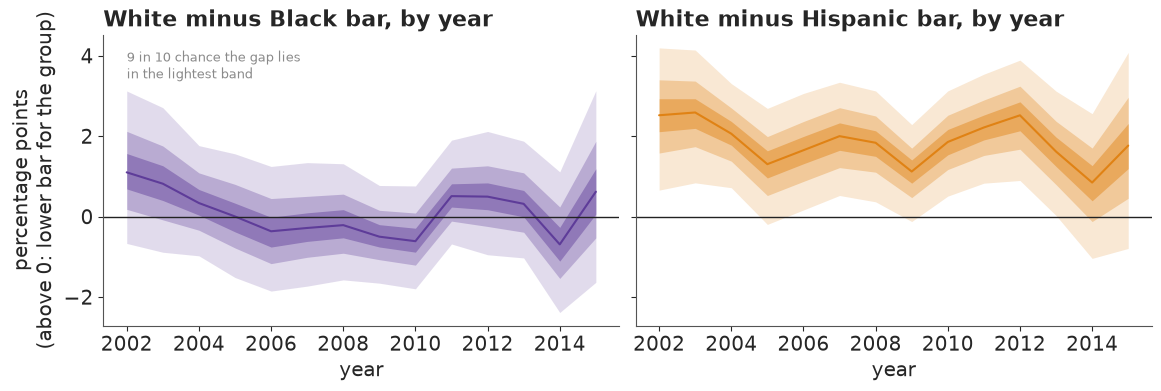

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.8), sharey=True)
yrs = np.array([int(y) for y in YEARS])
for ax, r in zip(axs, ("black", "hispanic")):
    for lvl, a in [(0.9, 0.18), (0.6, 0.30), (0.3, 0.45)]:
        lo_, hi_ = np.quantile(G_YR[r], [(1 - lvl) / 2, (1 + lvl) / 2], axis=0)
        ax.fill_between(yrs, lo_, hi_, color=RCOL[r], alpha=a, lw=0)
    ax.plot(yrs, np.median(G_YR[r], 0), color=RCOL[r], lw=1.5)
    ax.axhline(0, color=INK, lw=1)
    ax.set_title(f"White minus {NAME[r]} bar, by year", loc="left")
    ax.set_xlabel("year")
axs[0].set_ylabel("percentage points\n(above 0: lower bar for the group)")
axs[0].text(2002, axs[0].get_ylim()[1] * 0.92, "9 in 10 chance the gap lies\nin the lightest band", fontsize=9.5,
            color=MUTED, va="top");

The Black-white gap drifts from about +1 point in 2002 to about -0.5 around 2006-2010 and back,
dips in 2014 and widens in 2015, the year of the jump in the Black hit rate, but it never moves
clearly away from zero. The Hispanic gap stays above zero in almost every year at 1-2.5 points.
With independent years each year's gap rests on its own data, and the honest reading is "no
detectable change".

## F · What would change our mind?

### A second shape of suspicion

Part C showed that one unit cannot place a bar; part D placed it by assuming that every officer's
drivers follow the discriminant family. That family is a specific shape: a mixture of carriers
and non-carriers with a normal signal. Simoiu et al. (2017) used a beta distribution instead.
A natural alternative is the **logit-normal** family (B): the officer's estimate of the chance of
contraband, on the logit scale, is normal, $\operatorname{logit} r \sim N(m, s)$, a smooth
single-humped spread with no built-in split into "obvious" and "ordinary" drivers. Its search and
hit rates are

$$S = Q(z^*),\qquad H = \frac{1}{S}\int_{z^*}^{\infty}\operatorname{logit}^{-1}(m + s z)\,\varphi(z)\,dz,
\qquad z^* = \frac{\operatorname{logit} t - m}{s}.$$

The integral has no closed form. `rates_B` above computes it with 16-node Gauss-Legendre
quadrature on the nine standard deviations above the cut-off; against 64 nodes the error was
below $10^{-4}$ over the posterior range, and both families agreed with 2 million simulated
drivers in prototypes. Below we check the quadrature once more against simulation, then fit
family B with the same structure and priors (with $m_r \sim N(-3, 1)$ and
$\log s_r \sim N(0, 0.5)$).

In [15]:
for m0, s0, t0_ in [(-4.0, 1.5, 0.03), (-6.0, 2.5, 0.06), (-3.0, 0.8, 0.10)]:
    lsB, lhB = (v.eval() for v in rates_B(pt.as_tensor(m0), pt.as_tensor(np.log(s0)), pt.as_tensor(logit(t0_))))
    zz = rng.normal(size=2_000_000)
    rr = expit(m0 + s0 * zz)
    print(f"m {m0}, s {s0}, bar {t0_:.0%}: quadrature S {expit(lsB):.4f}, H {expit(lhB):.4f};  "
          f"simulated S {(rr > t0_).mean():.4f}, H {rr[rr > t0_].mean():.4f}")

t0 = time.time()
FIT_B = fit(OFF, UNITS, RACES, "B", "B · officers", loo=True)
TIMES["officers B"] = time.time() - t0
report(FIT_B)
report(FIT_B, W_OFF, " (214 named officers only)")
for other in ("black", "hispanic"):
    p = (officer_gaps(FIT_B, other) > 0).mean(0)
    print(f"B · officers, white minus {NAME[other]}: probably lower bar for {NAME[other]} drivers {(p > 0.9).sum()}, "
          f"probably higher {(p < 0.1).sum()}")

t0 = time.time()
FIT_B_LOW = fit(OFF, UNITS, RACES, "B", "B · officers, lower prior", draws=300, ppc=False, prior=LOW_PRIOR["B"])
TIMES["officers B, lower prior"] = time.time() - t0
report(FIT_B_LOW)
for res in (FIT_B, FIT_B_LOW):
    ratios(res)
del FIT_B_LOW

m -4.0, s 1.5, bar 3%: quadrature S 0.3634, H 0.1019;  simulated S 0.3629, H 0.1019
m -6.0, s 2.5, bar 6%: quadrature S 0.0969, H 0.2069;  simulated S 0.0971, H 0.2070
m -3.0, s 0.8, bar 10%: quadrature S 0.1578, H 0.1503;  simulated S 0.1581, H 0.1503


B · officers: 57 s (warm-up 600), divergences 0, tree depth mean 6.9 max 7
   r_hat: race-level means up to 1.066 (bulk ESS from 64); average bars up to 1.062; gaps up to 1.024 (ESS from 256); unit bars up to 1.060
   scales (median, 89%): s_a 0.21 (0.05-0.42), s_b 0.24 (0.22-0.27), s_c 0.60 (0.54-0.68), s_e 0.36 (0.32-0.42)


   check Black    : search rate 5.06% observed, 4.96%-5.13% replicated; hits 3,198 observed, 3,084-3,308 replicated
   check white    : search rate 2.47% observed, 2.43%-2.53% replicated; hits 1,270 observed, 1,194-1,350 replicated
   check Hispanic : search rate 5.22% observed, 5.10%-5.40% replicated; hits 359 observed, 324-413 replicated
   cells inside their 89% predictive range: searches 100%, hits 97%


   PSIS-LOO: elpd -3,543 (se 44), p_loo 629 for 645 cells, Pareto k > 0.7 for 71% of cells
B · officers: average bars Black 6.1% (5.2%-6.9%), white 6.6% (5.8%-7.4%), Hispanic 3.5% (2.9%-4.2%)
   white minus Black: +0.5 [-0.2, +1.2] points, P(lower bar for Black drivers) 0.87
   white minus Hispanic: +3.0 [+2.3, +3.8] points, P(lower bar for Hispanic drivers) 1.00
B · officers (214 named officers only): average bars Black 5.7% (4.9%-6.4%), white 5.7% (4.9%-6.5%), Hispanic 3.4% (2.9%-4.0%)
   white minus Black: +0.0 [-0.7, +0.8] points, P(lower bar for Black drivers) 0.54
   white minus Hispanic: +2.3 [+1.4, +3.0] points, P(lower bar for Hispanic drivers) 1.00
B · officers, white minus Black: probably lower bar for Black drivers 57, probably higher 34
B · officers, white minus Hispanic: probably lower bar for Hispanic drivers 124, probably higher 2


B · officers, lower prior: 40 s (warm-up 600), divergences 4, tree depth mean 6.6 max 7
   r_hat: race-level means up to 1.127 (bulk ESS from 24); average bars up to 1.091; gaps up to 1.018 (ESS from 124); unit bars up to 1.086
   scales (median, 89%): s_a 0.24 (0.05-0.48), s_b 0.23 (0.21-0.25), s_c 0.64 (0.57-0.72), s_e 0.41 (0.36-0.46)
B · officers, lower prior: average bars Black 5.4% (4.6%-6.1%), white 5.9% (5.1%-6.7%), Hispanic 3.1% (2.5%-3.7%)
   white minus Black: +0.5 [-0.2, +1.4] points, P(lower bar for Black drivers) 0.87
   white minus Hispanic: +2.8 [+2.0, +3.6] points, P(lower bar for Hispanic drivers) 1.00
B · officers: white bar / Hispanic bar 1.9, white / Black 1.09
B · officers, lower prior: white bar / Hispanic bar 1.9, white / Black 1.10


Family B matches the rates as closely as A (and, as with A, that check could not have failed) and
has the same level ridge (r_hat up to about 1.07 for the race-level means), with gaps that mix
well (1.02). Its bars are higher overall (about 6-6.5% for Black and white drivers, 3.5% for
Hispanic drivers), again a statement about the soft level. The Hispanic gap is about 3 points,
against 2.3 under A. The Black-white gap has **changed sign**: about +0.5 points, a lower bar for
Black drivers, with probability nearly 9 in 10. Over the 214 named officers it is about zero. The
officer-level picture flips as well: under B about 57 officers appear to hold Black drivers to a
lower bar and about 34 to a higher one. Even the robust result leans on the shape officer by
officer: the number of officers individually showing a lower bar for Hispanic drivers falls from
about 190 under A to about 125 under B.

B's lower-prior refit, printed last, mixes better than A's but is also only indicative at 300
draws (race-level r_hat 1.13, gap ESS about 120, four divergences). It lowers the bars by about
half a point and leaves both answers where they were: the Hispanic gap at about 2.8 points, the
Black-white gap at about +0.5 with a lower bar for Black drivers nearly 9 chances in 10. Under
both shapes the prior moves the level and not the signs.

### Can the data choose the shape?

Both families reproduce every rate, so a predictive check on the fitted rates cannot choose.
PSIS-LOO was computed for both fits, leaving out one officer-by-race cell (its searches and hits
together) at a time.

In [16]:
for res in (FIT_A, FIT_B):
    lo = res["loo"]
    print(f"{res['label']}: elpd {lo['elpd']:,.0f} (se {lo['se']:.0f}), p_loo {lo['p']:,.0f}, "
          f"Pareto k > 0.7 for {lo['k_bad']:.0%} of the {len(OFF)} cells")
d_ = FIT_B["loo"]["elpd_i"] - FIT_A["loo"]["elpd_i"]
print(f"difference B - A: {d_.sum():+.0f} (se of the paired difference {np.sqrt(d_.size) * d_.std():.0f})")

A · officers: elpd -3,562 (se 47), p_loo 625, Pareto k > 0.7 for 66% of the 645 cells
B · officers: elpd -3,543 (se 44), p_loo 629, Pareto k > 0.7 for 71% of the 645 cells
difference B - A: +19 (se of the paired difference 12)


Family B is ahead by about 19 points, with a standard error of the paired difference of about 12:
less than two standard errors, and in any case the numbers cannot be trusted. Two thirds or more
of the cells have Pareto $k$ above 0.7, and p_loo, about 630, is close to one per cell: leaving a
cell out changes the posterior a lot and the importance weights blow up. Exact K-fold
cross-validation would mean dozens of refits of a minute-long model, beyond this notebook's
budget. **The data do not choose the shape of suspicion.**

### Placebo worlds: what a wrong shape does

So how much can the shape matter? Simoiu et al. (2017) checked their test on simulated data, and
we do the same with a sharper question. We build two **placebo worlds** on the real officer table
(same officers, same numbers of stops) in which, by construction, every officer holds every race
to *the same* bar, while the risk distributions differ by race. World 1 is drawn from family A,
World 2 from family B. The parameters were chosen so that each world fools the outcome test, not
to match Raleigh: World 1's hit rates are about twice Raleigh's, World 2's search rates too. So
the gaps they produce show what a wrong shape *can* do, not a calibrated size to set against the
real gaps; each world is also a single draw. Then we fit each world with both families. A correct
test finds gaps near zero. To keep within the time budget these fits use 600 warm-up steps and
only 300 draws per chain.

In [17]:
def placebo_world(family, a_r, b_r, c, sds, seed):
    """Searches and hits on the real officer table when every officer has ONE bar for all races."""
    g = np.random.default_rng(seed)
    ui = pd.Index(UNITS).get_indexer(OFF.u)
    ri = pd.Index(RACES).get_indexer(OFF.race)
    za, zb, zc = g.normal(size=(3, len(UNITS)))
    A = np.asarray(a_r)[ri] + sds[0] * za[ui]
    B = np.asarray(b_r)[ri] + sds[1] * zb[ui]
    LT = c + sds[2] * zc[ui]
    if family == "A":
        S, Hr = rates_np(expit(A), np.exp(B), expit(LT))
    else:
        sd = np.exp(B)
        zs = (LT - A) / sd
        S = norm.sf(zs)
        zz = zs[:, None] + np.linspace(0, 12, 4001)[None, :]
        Hr = np.trapezoid(expit(A[:, None] + sd[:, None] * zz) * norm.pdf(zz), zz, axis=1) / S
    sim = OFF[["u", "race", "stops"]].copy()
    sim["searches"] = g.binomial(sim.stops, S)
    sim["hits"] = g.binomial(sim.searches, Hr)
    agg = sim.groupby("race")[["stops", "searches", "hits"]].sum().reindex(RACES)
    print(f"World from family {family}: " + "; ".join(
        f"{NAME[r]} searched {1000 * agg.searches[r] / agg.stops[r]:.0f} per 1,000, hit rate "
        f"{agg.hits[r] / agg.searches[r]:.0%}" for r in RACES))
    return sim


WORLDS = {"World 1 (family A)": placebo_world("A", [-4.0, -4.6, -4.4], [0.8, 0.95, 0.5], -2.6, (0.88, 0.16, 0.25), 7),
          "World 2 (family B)": placebo_world("B", [-6.3, -6.9, -6.3], [0.92, 0.8, 0.7], -3.0, (0.23, 0.22, 0.5), 8)}
PLACEBO = {}
t0 = time.time()
for wname, sim in WORLDS.items():
    for fam in ("A", "B"):
        res = fit(sim, UNITS, RACES, fam, f"{wname}, fitted by {fam}", draws=300, ppc=False)
        report(res)
        PLACEBO[(wname, fam)] = {r: gap(res, W_ALL, r) for r in ("black", "hispanic")}
        del res
TIMES["placebo"] = time.time() - t0
P_NULL = {(w, f, r): float((g_ > 0).mean()) for (w, f), d in PLACEBO.items() for r, g_ in d.items()}
N_SURE99 = sum(p >= 0.99 or p <= 0.01 for p in P_NULL.values())
N_SURE95 = sum(p >= 0.95 or p <= 0.05 for p in P_NULL.values())
N_AGREE = sum(min(P_NULL[(w, "A", r)], P_NULL[(w, "B", r)]) > 0.9 or max(P_NULL[(w, "A", r)], P_NULL[(w, "B", r)]) < 0.1
              for w in WORLDS for r in ("black", "hispanic"))
print(f"\n{len(P_NULL)} placebo gaps, all truly zero: {N_SURE95} have P(lower) above 0.95 or below 0.05, "
      f"{N_SURE99} above 0.99 or below 0.01; both shapes agree on a gap (P > 0.9 or < 0.1 under each) "
      f"in {N_AGREE} of {len(P_NULL) // 2} world x race cases")

World from family A: Black searched 58 per 1,000, hit rate 26%; white searched 29 per 1,000, hit rate 28%; Hispanic searched 35 per 1,000, hit rate 17%
World from family B: Black searched 117 per 1,000, hit rate 21%; white searched 61 per 1,000, hit rate 16%; Hispanic searched 73 per 1,000, hit rate 16%


World 1 (family A), fitted by A: 22 s (warm-up 600), divergences 0, tree depth mean 5.2 max 9
   r_hat: race-level means up to 1.473 (bulk ESS from 8); average bars up to 1.427; gaps up to 1.224 (ESS from 13); unit bars up to 1.360
   scales (median, 89%): s_a 0.76 (0.64-0.87), s_b 0.15 (0.12-0.21), s_c 0.21 (0.13-0.29), s_e 0.03 (0.00-0.07)
World 1 (family A), fitted by A: average bars Black 8.5% (6.6%-11.0%), white 8.1% (6.0%-10.6%), Hispanic 8.6% (7.6%-9.9%)
   white minus Black: -0.4 [-1.1, +0.3] points, P(lower bar for Black drivers) 0.15
   white minus Hispanic: -0.5 [-2.1, +1.2] points, P(lower bar for Hispanic drivers) 0.34


World 1 (family A), fitted by B: 32 s (warm-up 600), divergences 0, tree depth mean 6.0 max 6
   r_hat: race-level means up to 1.381 (bulk ESS from 10); average bars up to 1.331; gaps up to 1.073 (ESS from 46); unit bars up to 1.298
   scales (median, 89%): s_a 0.73 (0.64-0.83), s_b 0.04 (0.00-0.08), s_c 0.35 (0.30-0.41), s_e 0.05 (0.02-0.08)
World 1 (family A), fitted by B: average bars Black 12.9% (11.6%-14.2%), white 14.1% (12.5%-15.6%), Hispanic 9.9% (8.8%-11.0%)
   white minus Black: +1.2 [+0.4, +2.0] points, P(lower bar for Black drivers) 0.99
   white minus Hispanic: +4.2 [+3.0, +5.3] points, P(lower bar for Hispanic drivers) 1.00


World 2 (family B), fitted by A: 40 s (warm-up 600), divergences 0, tree depth mean 6.5 max 9
   r_hat: race-level means up to 1.025 (bulk ESS from 119); average bars up to 1.016; gaps up to 1.010 (ESS from 407); unit bars up to 1.018
   scales (median, 89%): s_a 0.89 (0.81-1.00), s_b 0.04 (0.02-0.06), s_c 0.42 (0.36-0.49), s_e 0.03 (0.00-0.07)
World 2 (family B), fitted by A: average bars Black 2.8% (1.9%-4.0%), white 5.3% (4.5%-6.2%), Hispanic 5.2% (4.3%-6.1%)
   white minus Black: +2.5 [+1.9, +3.0] points, P(lower bar for Black drivers) 1.00
   white minus Hispanic: +0.1 [-0.5, +0.7] points, P(lower bar for Hispanic drivers) 0.62


World 2 (family B), fitted by B: 34 s (warm-up 600), divergences 0, tree depth mean 6.0 max 6
   r_hat: race-level means up to 1.273 (bulk ESS from 11); average bars up to 1.221; gaps up to 1.046 (ESS from 66); unit bars up to 1.185
   scales (median, 89%): s_a 0.12 (0.01-0.30), s_b 0.26 (0.23-0.28), s_c 0.35 (0.31-0.40), s_e 0.01 (0.00-0.04)
World 2 (family B), fitted by B: average bars Black 7.0% (6.0%-8.1%), white 6.7% (5.9%-7.5%), Hispanic 7.6% (6.6%-8.6%)
   white minus Black: -0.3 [-0.9, +0.3] points, P(lower bar for Black drivers) 0.22
   white minus Hispanic: -0.9 [-1.7, -0.1] points, P(lower bar for Hispanic drivers) 0.04

8 placebo gaps, all truly zero: 4 have P(lower) above 0.95 or below 0.05, 3 above 0.99 or below 0.01; both shapes agree on a gap (P > 0.9 or < 0.1 under each) in 0 of 4 world x race cases


Both worlds have equal bars by construction, and in both the **outcome test is fooled**. In
World 1, Hispanic drivers' searches succeed much less often than white drivers' (17% against 28%)
and Black drivers' a little less (26%), which an outcome test would read as bias against both. In
World 2 the Black hit rate is 5 points *higher* than the white one, which it would read as a
higher bar for Black drivers.

First, the diagnostics, because they are worse than on the real data. The level ridge is much
more pronounced in these worlds, and with short runs the race-level means reach r_hat 1.3-1.5 in
three of the four fits, with ESS near 10. World 1 fitted by A is not converged even for the gaps
(r_hat 1.22, ESS about 13), so we do not read it as recovering anything. The gaps of the other
fits mix better: r_hat 1.05-1.07 for the two short-mixing ones, 1.01 for World 2 fitted by A. We
read them for gaps of a point or more, not for decimals.

That leaves one fit with the **right** family to judge recovery by, World 2 fitted by B, and it
missed: a Black-white gap near zero, but a Hispanic gap of about -0.9 points whose 89% interval,
-1.7 to -0.1, excludes zero. With the **wrong** family the test invents larger gaps. B fitted to
World 1 finds a lower bar for Black drivers by about 1.2 points and for Hispanic drivers by about
4 points, both near certain. A fitted to World 2 finds a lower bar for Black drivers by about 2.5
points with clean diagnostics (race-level r_hat 1.03, gaps 1.01, no divergences). B on World 1
mixes the level poorly (r_hat 1.38), but no worse than the right-shape fit of the same world
(1.47), so the warnings cannot tell right from wrong.

The last line counts the damage. Of the eight gaps, all truly zero, four got a probability above
95% one way or the other and three above 99%: the posterior probabilities of a single shape are
not calibrated outcome probabilities, and "above 99%" from one fit is no guarantee. What the
worlds never produced is the two shapes *agreeing* on a false gap: in every case where one shape
was sure, the other was not, or leaned the other way.

Set this beside the real fits. For Black drivers, A says -0.3 and B says +0.5 points, which is
exactly the disagreement the placebo fits show, and a gap that small cannot be told from noise or
from a wrong shape. For Hispanic drivers, both families say a lower bar by 2.3-3 points. That
agreement is the evidence the placebo study supports; World 1 shows that family B alone can
produce a Hispanic gap of 4 points from nothing, so "robust across two shapes" is the most we can
claim, not "proven".

### Consent searches

Part A found that a third of the searches of Black drivers were consent searches, asked for 2.7
times as often as from white drivers and less often successful. A consent search needs no
suspicion beyond the officer's wish to ask, so it is a natural place for a lower bar to hide.
Refitting both families without them would cost two more minutes, so it is left as the first
exercise below.

### Stops themselves

Everything above conditions on the stop. If officers stop Black drivers on weaker grounds, the
stopped Black drivers include more people with nothing to find, and a test that takes the stopped
population as given can understate or hide discrimination, whatever its risk family (Knox, Lowe &
Mummolo 2020). Raleigh's records cannot tell us who was *not* stopped.

### Everything at once

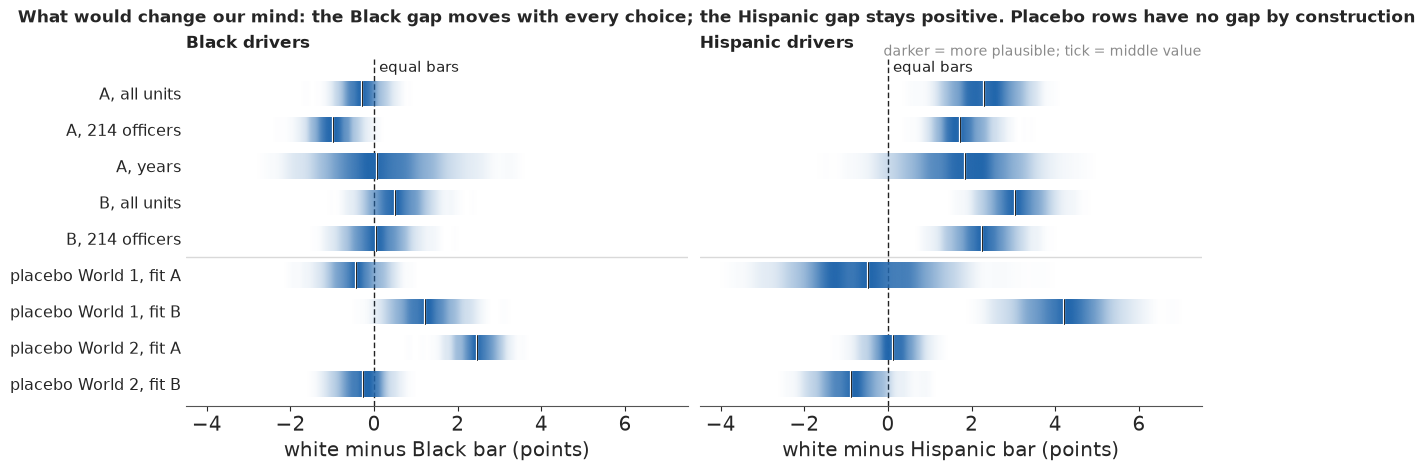

In [18]:
ROWS = [("A, all units", FIT_A, W_ALL), ("A, 214 officers", FIT_A, W_OFF), ("A, years", FIT_Y, W_YR),
        ("B, all units", FIT_B, W_ALL), ("B, 214 officers", FIT_B, W_OFF)]
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6), sharex=True)
for ax, r in zip(axs, ("black", "hispanic")):
    draws = [gap(res, w, r) for _, res, w in ROWS] + [PLACEBO[k][r] for k in PLACEBO]
    names = [n for n, _, _ in ROWS] + [f"placebo {k[0][:7]}, fit {k[1]}" for k in PLACEBO]
    pub.gradient_intervals(ax, draws, names, xlim=(-4.5, 7.5), ref=0, ref_label="equal bars",
                           xlabel=f"white minus {NAME[r]} bar (points)", key=(r == "hispanic"),
                           title=f"{NAME[r]} drivers")
    ax.axhline(len(PLACEBO) - 0.5, color=LIGHT, lw=1)
axs[1].set_yticklabels([])
fig.suptitle("What would change our mind: the Black gap moves with every choice; the Hispanic gap stays "
             "positive. Placebo rows have no gap by construction", x=0.01, ha="left", fontsize=12);

The bottom four rows are placebo fits whose true gap is zero. On the left the Black-white gap
crosses zero as we change the risk family or the units we average over, by about as much as the
gaps a wrong family invents. On the right the Hispanic gap is positive in every real-data row,
about 1.7-3 points.

### Pooling the two shapes

For the public summary we need one number per question. Since the data cannot choose between the
two families, we give them equal weight - a stated prior over models, not a result - and pool
their draws.

In [19]:
MIX = {r: np.r_[gap(FIT_A, W_ALL, r).ravel(), gap(FIT_B, W_ALL, r).ravel()] for r in ("black", "hispanic")}
P_LOWER = {r: float((MIX[r] > 0).mean()) for r in MIX}
MIX_OFF = {r: np.r_[gap(FIT_A, W_OFF, r).ravel(), gap(FIT_B, W_OFF, r).ravel()] for r in ("black", "hispanic")}
P_LOWER_OFF = {r: float((MIX_OFF[r] > 0).mean()) for r in MIX_OFF}
for lab, mx, pl in (("all units", MIX, P_LOWER), ("214 named officers", MIX_OFF, P_LOWER_OFF)):
    for r in mx:
        print(f"A and B pooled, {lab}, white minus {NAME[r]}: {q89(mx[r])} points; P(lower bar for {NAME[r]} "
              f"drivers) {pl[r]:.2f} -> {pub.calibrated_word(pl[r])} ({pub.fmt_pct(pl[r])})")

A and B pooled, all units, white minus Black: +0.0 [-0.7, +1.1] points; P(lower bar for Black drivers) 0.52 -> about as likely as not (52%)
A and B pooled, all units, white minus Hispanic: +2.7 [+1.6, +3.6] points; P(lower bar for Hispanic drivers) 1.00 -> virtually certain (>99%)
A and B pooled, 214 named officers, white minus Black: -0.6 [-1.4, +0.6] points; P(lower bar for Black drivers) 0.27 -> unlikely (27%)
A and B pooled, 214 named officers, white minus Hispanic: +2.0 [+1.2, +2.9] points; P(lower bar for Hispanic drivers) 1.00 -> virtually certain (>99%)


Pooled, the Hispanic gap is about 2.7 points and the Black-white gap about zero, with a lower bar
for Black drivers about as likely as not. The Black interval is wide because it straddles two
models that disagree, and it is honest only if the two families span the plausible shapes. Over
the 214 named officers alone the pooled Black-white gap is about -0.6 points (a lower bar
unlikely, 27%) and the Hispanic gap about 2. The public statement uses all units, the city as its
drivers met it.

## G · Explaining it to everyone

### The statistician's plots

Two figures carry this analysis for a technical reader: the outcome test as published (hit rates
with 95% intervals) and the threshold test as a forest plot of gaps with 89% intervals.

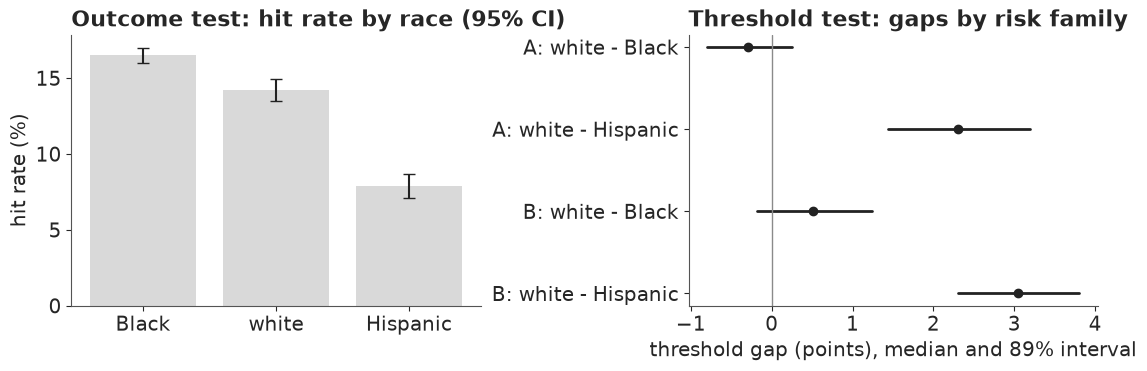

In [20]:
CITY_S = {r: rng.beta(1 + city.searches[r], 1 + city.stops[r] - city.searches[r], 4000) for r in RACES}
CITY_H = {r: rng.beta(1 + city.hits[r], 1 + city.searches[r] - city.hits[r], 4000) for r in RACES}
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for i, r in enumerate(RACES):
    lo, hi = np.quantile(CITY_H[r], [0.025, 0.975])
    m_ = CITY_H[r].mean()
    axs[0].bar(i, 100 * m_, color=LIGHT)
    axs[0].errorbar(i, 100 * m_, [[100 * (m_ - lo)], [100 * (hi - m_)]], color=INK, capsize=4)
axs[0].set_xticks(range(3), [NAME[r] for r in RACES])
axs[0].set_ylabel("hit rate (%)")
axs[0].set_title("Outcome test: hit rate by race (95% CI)", loc="left")
k_ = 0
for fam, res in (("A", FIT_A), ("B", FIT_B)):
    for r in ("black", "hispanic"):
        lo, mid, hi = np.quantile(gap(res, W_ALL, r), [0.055, 0.5, 0.945])
        axs[1].plot([lo, hi], [k_, k_], color=INK, lw=2)
        axs[1].plot(mid, k_, "o", color=INK)
        k_ += 1
axs[1].axvline(0, color=MUTED, lw=1)
axs[1].set_yticks(range(4), ["A: white - Black", "A: white - Hispanic", "B: white - Black", "B: white - Hispanic"])
axs[1].invert_yaxis()
axs[1].set_xlabel("threshold gap (points), median and 89% interval")
axs[1].set_title("Threshold test: gaps by risk family", loc="left");

Both are correct and both fail a general reader. The bar chart is the outcome test, which part B
showed can point the wrong way, and its tiny intervals make it look conclusive. The forest plot
speaks of "gaps" in thresholds nobody has met, with hard interval ends that readers take as limits
(Correll & Gleicher 2014) and two rows per question with no hint of why they differ.

### The headline: three trees and a gap

The headline display starts from what readers can picture: 10,000 drivers of each group,
stopped. A **natural-frequency tree** splits them into searched and not searched, and the
searched into contraband found and nothing found. Counts out of a fixed number are understood far
better than conditional percentages (Gigerenzer & Hoffrage 1995; the Cochrane review of Akl et
al. 2011). We use 10,000 rather than 1,000 because at 1,000 the rounding would print 8 of 51 and
4 of 25, the same 16%, and erase the very difference the outcome test reads. The trees are the
record, not the model: their counts are known to within a few drivers per 10,000, so we leave the
ranges out and put the uncertainty where it lives, in the bar.

Beside the trees a **gap panel** answers the question in the title: how much lower is the bar
for Black and for Hispanic drivers than for white drivers? We draw the gap, not the bars
themselves, because the level of the bar is the soft part of the model. Each group gets two
strips, one per assumption about the shape of suspicion, drawn as **gradient intervals** whose
darkness follows the posterior density; gradients avoid the false precision of interval ends
(Correll & Gleicher 2014). The zero line and the two directions are labelled in words. Two strips
per group, rather than one blended strip with two humps, show at a glance that the Black gap
changes side with the assumption and the Hispanic one does not. The title states the finding as
conditional on the shapes.

{'black': '506 searched, 83 found per 10,000', 'white': '247 searched, 35 found per 10,000', 'hispanic': '522 searched, 41 found per 10,000'} {'black': '2.05x white', 'white': '1.00x white', 'hispanic': '2.11x white'} {'A': {'black': 0.18, 'hispanic': 1.0}, 'B': {'black': 0.869, 'hispanic': 1.0}}


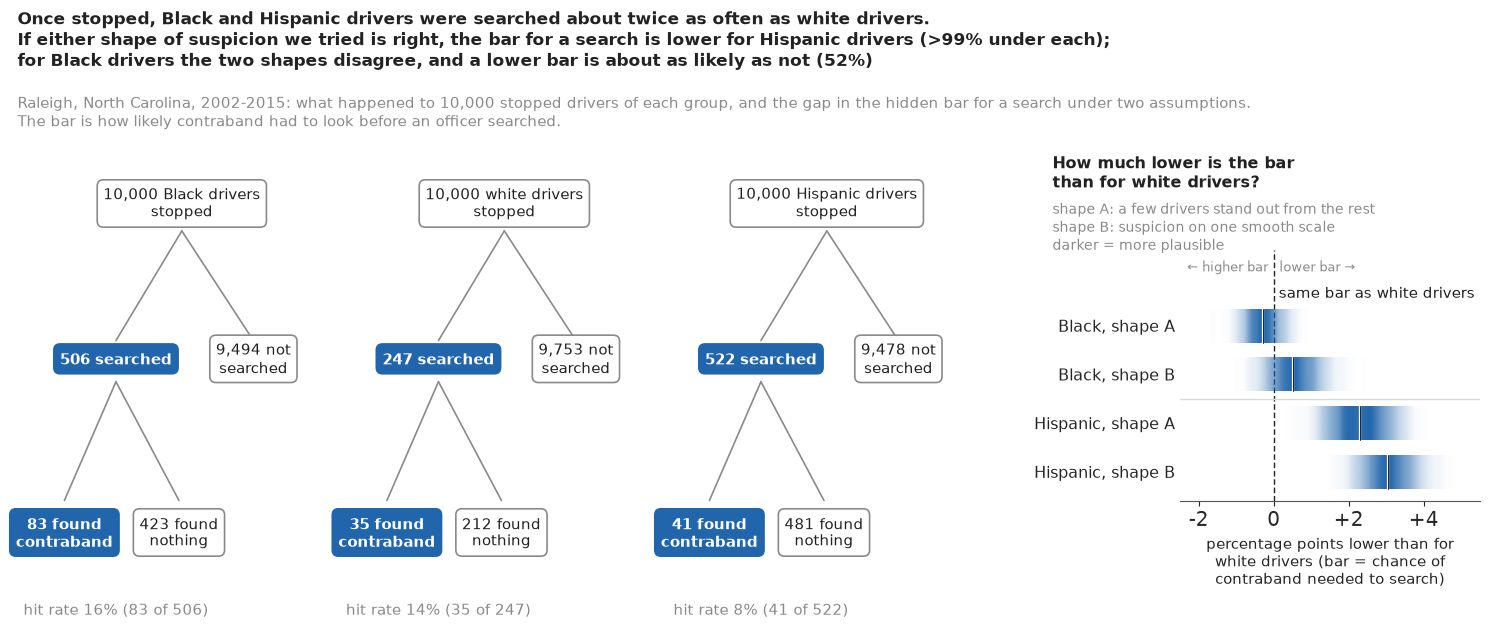

In [21]:
GROUPS = [(r, f"{NAME[r]} drivers") for r in RACES]
T_A, T_B = (avg_bars(res, W_ALL).reshape(-1, 3) for res in (FIT_A, FIT_B))
RATIO = {r: np.median(CITY_S[r] / CITY_S["white"]) for r in RACES}
SHAPE = {"A": "a few drivers stand out from the rest", "B": "suspicion on one smooth scale"}


def search_tree(ax, N, s_draws, h_draws, label, color=HI):
    """Root -> searched / not searched; searched -> contraband found / nothing found. Counts that add up."""
    a = int(round(N * np.mean(s_draws)))
    f = int(round(a * np.mean(h_draws)))
    box = lambda hot: dict(boxstyle="round,pad=0.4", fc=color if hot else "white", ec=color if hot else MUTED, lw=1.2)

    def node(x, y, txt, hot=False):
        ax.text(x, y, txt, ha="center", va="center", fontsize=11, color="white" if hot else INK,
                weight="bold" if hot else "normal", bbox=box(hot), linespacing=1.15, zorder=3)

    for x0, y0, x1, y1 in [(0.5, 0.86, 0.27, 0.62), (0.5, 0.86, 0.75, 0.62), (0.27, 0.53, 0.09, 0.27),
                           (0.27, 0.53, 0.49, 0.27)]:
        ax.plot([x0, x1], [y0, y1], color=MUTED, lw=1.2, zorder=1)
    node(0.5, 0.92, f"{N:,} {label}\nstopped")
    node(0.27, 0.58, f"{a} searched", hot=True)
    node(0.75, 0.58, f"{N - a:,} not\nsearched")
    node(0.09, 0.2, f"{f} found\ncontraband", hot=True)
    node(0.49, 0.2, f"{a - f} found\nnothing")
    ax.text(0.27, 0.02, f"hit rate {f / a:.0%} ({f} of {a})", ha="center", fontsize=10.5, color=MUTED)
    ax.set_xlim(-0.1, 1.0)
    ax.set_ylim(-0.02, 1.02)
    ax.axis("off")
    return a, f


def gap_panel(ax, fits=(("A", FIT_A), ("B", FIT_B)), xlim=(-2.5, 5.5)):
    """White bar minus each group's bar, one gradient strip per risk shape; zero = the same bar as white drivers."""
    draws = [gap(res, W_ALL, r) for r in ("black", "hispanic") for _, res in fits]
    names = [f"{NAME[r]}, shape {fam}" for r in ("black", "hispanic") for fam, _ in fits]
    pub.gradient_intervals(ax, draws, names, xlim=xlim, ref=0, ref_label="same bar as white drivers", key=False,
                           xlabel="percentage points lower than for\nwhite drivers (bar = chance of\n"
                                  "contraband needed to search)")
    ax.xaxis.label.set_fontsize(10.5)
    ax.set_ylim(-0.6, 4.55)
    ax.text(-0.15, 4.05, "← higher bar", ha="right", va="bottom", fontsize=9.5, color=MUTED)
    ax.text(0.15, 4.05, "lower bar →", ha="left", va="bottom", fontsize=9.5, color=MUTED)
    ax.axhline(1.5, color=LIGHT, lw=1)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0f}" if v else "0"))


P_SHAPE = {fam: {r: float((gap(res, W_ALL, r) > 0).mean()) for r in ("black", "hispanic")}
           for fam, res in (("A", FIT_A), ("B", FIT_B))}
P_HISP_EACH = min(P_SHAPE["A"]["hispanic"], P_SHAPE["B"]["hispanic"])
HEAD_TITLE = (f"Once stopped, Black and Hispanic drivers were searched about twice as often as white drivers.\n"
              f"If either shape of suspicion we tried is right, the bar for a search is lower for Hispanic drivers "
              f"({pub.fmt_pct(P_HISP_EACH)} under each);\nfor Black drivers the two shapes disagree, and a lower bar is "
              f"{pub.calibrated_word(P_LOWER['black'])} ({pub.fmt_pct(P_LOWER['black'])})")
N_TREE = 10_000
fig_head = plt.figure(figsize=(15, 6.6), layout="none")
COUNTS = {}
for j, (r, name) in enumerate(GROUPS):
    COUNTS[r] = search_tree(fig_head.add_axes([0.005 + 0.215 * j, 0.04, 0.21, 0.72]), N_TREE, CITY_S[r], CITY_H[r],
                            name)
axg = fig_head.add_axes([0.785, 0.24, 0.20, 0.38])
gap_panel(axg)
fig_head.text(0.70, 0.765, "How much lower is the bar\nthan for white drivers?", fontsize=11.5, color=INK,
              weight="bold", va="top")
fig_head.text(0.70, 0.695, f"shape A: {SHAPE['A']}\nshape B: {SHAPE['B']}\ndarker = more plausible",
              fontsize=10, color=MUTED, va="top", linespacing=1.3)
fig_head.suptitle(HEAD_TITLE, x=0.01, ha="left", fontsize=12.5, color=INK, y=0.985, weight="bold")
fig_head.text(0.01, 0.80, f"Raleigh, North Carolina, 2002-2015: what happened to {N_TREE:,} stopped drivers of each "
              "group, and the gap in the hidden bar for a search under two assumptions.\nThe bar is how likely "
              "contraband had to look before an officer searched.", fontsize=11, color=MUTED, va="bottom")
HEADLINE.update(fig_head)
print({r: f"{a} searched, {f} found per {N_TREE:,}" for r, (a, f) in COUNTS.items()},
      {r: f"{RATIO[r]:.2f}x white" for r in RACES}, {k: {r: round(p, 3) for r, p in v.items()} for k, v in P_SHAPE.items()})

The trees give the record in counts anyone can check: for every 10,000 stopped drivers of each
group, 506 Black, 247 white and 522 Hispanic drivers were searched, and contraband was found on
83, 35 and 41. The gap panel gives the model's answer. Both Hispanic strips sit to the right of
the zero line, at about 2.3 and 3 points: under either shape, officers needed less suspicion to
search a Hispanic driver. The two Black strips sit one on each side of it. The same figure opens
the notebook as the plain-words headline.

Trees of observed counts have a pitfall of their own: they look certain, and they are, but they
answer "what happened", not "was the bar the same", and a reader can still take the hit rates in
the trees as the answer. The gap panel beside them is there to stop that.

### The bar itself, and the hit rate

A supporting ladder puts the bars on the scale of the chance of carrying contraband, beside each
group's hit rate, one panel per shape. Every bar sits far below its group's hit rate, which is
part B's lesson; and shape B puts every bar about 3 points higher than shape A, so only strips
within one panel should be compared.

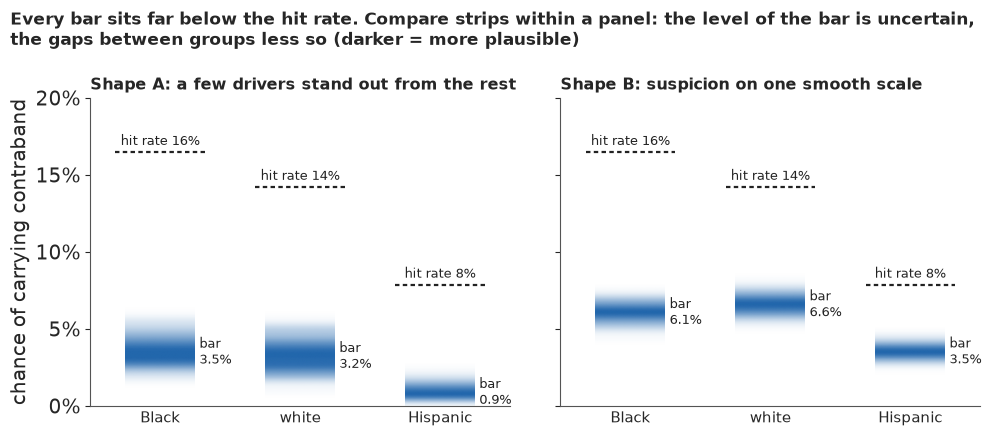

In [22]:
def ladder(ax, T, ymax=0.2):
    """'Bar for a search' ladder for one risk shape: a gradient strip per group, the hit rate as a dashed line."""
    grid = np.linspace(0, ymax, 401)
    for i, (r, _) in enumerate(GROUPS):
        d = T[:, RACES.index(r)]
        dens = np.histogram(d, bins=grid)[0].astype(float)
        k = np.exp(-0.5 * (np.arange(-12, 13) / 4) ** 2)
        dens = np.convolve(dens, k / k.sum(), "same")
        dens /= dens.max()
        img = np.zeros((dens.size, 1, 4))
        img[..., :3] = to_rgb(HI)
        img[..., 0, 3] = dens**0.8
        ax.imshow(img, extent=(i - 0.25, i + 0.25, 0, ymax), aspect="auto", origin="lower",
                  interpolation="bilinear", zorder=2)
        hm = np.mean(CITY_H[r])
        ax.plot([i - 0.32, i + 0.32], [hm, hm], color=INK, lw=1.6, ls=(0, (2, 1.5)), zorder=4)
        ax.text(i, hm + ymax * 0.012, f"hit rate {hm:.0%}", ha="center", va="bottom", fontsize=9.5, color=INK)
        ax.text(i + 0.28, np.median(d), f"bar\n{np.median(d):.1%}", ha="left", va="center", fontsize=9.5,
                color=INK)
    ax.set_xlim(-0.5, len(GROUPS) - 0.5)
    ax.set_ylim(0, ymax)
    ax.set_xticks(range(len(GROUPS)), [NAME[r] for r, _ in GROUPS], fontsize=11)
    ax.tick_params(axis="x", length=0)
    ax.set_yticks(np.arange(0, ymax + 1e-9, 0.05))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    for s_ in ("top", "right"):
        ax.spines[s_].set_visible(False)


fig, axs = plt.subplots(1, 2, figsize=(10, 4.4), sharey=True, layout="none")
fig.subplots_adjust(left=0.09, right=0.98, top=0.78, bottom=0.08, wspace=0.12)
for ax, (fam, T) in zip(axs, (("A", T_A), ("B", T_B))):
    ladder(ax, T)
    ax.set_title(f"Shape {fam}: {SHAPE[fam]}", loc="left", fontsize=11.5)
axs[0].set_ylabel("chance of carrying contraband")
fig.suptitle("Every bar sits far below the hit rate. Compare strips within a panel: the level of the bar is "
             "uncertain,\nthe gaps between groups less so (darker = more plausible)", x=0.01, ha="left",
             fontsize=12, weight="bold");

Within each panel the Hispanic strip sits well below the other two. Across panels the strips do
not line up: shape A's white bar is below shape B's Hispanic bar, which is why the headline shows
the gap.

### Calibrated words

It is *virtually certain* (>99%) that the bar is lower for Hispanic drivers than for white drivers, if either shape we tried is right. We have *medium confidence* in that figure: in test worlds with equal bars one shape alone gave 3 of 8 false gaps such odds, but the two shapes never agreed on one.
It is *about as likely as not* (52%) that the bar is lower for Black drivers, weighing the two shapes equally. We have *low confidence* in that figure: it turns on a shape the data cannot check.


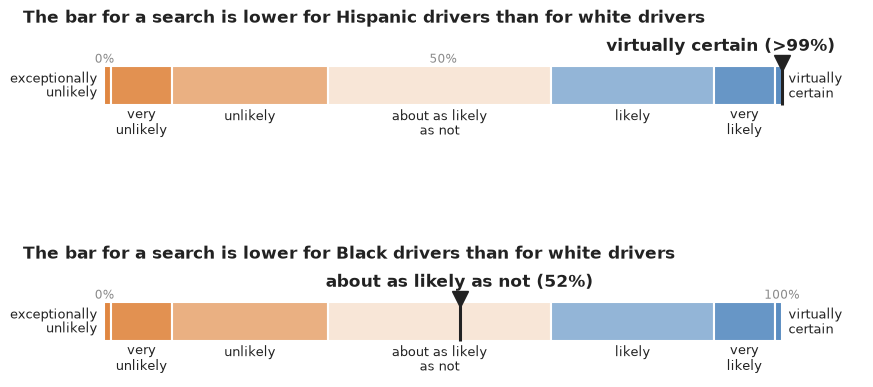

In [23]:
fig, axs = plt.subplots(2, 1, figsize=(10, 4.4), layout="none")
fig.subplots_adjust(left=0.08, right=0.92, top=0.86, bottom=0.08, hspace=1.2)
pub.word_strip(axs[0], P_LOWER["hispanic"], "The bar for a search is lower for Hispanic drivers than for white drivers")
pub.word_strip(axs[1], P_LOWER["black"], "The bar for a search is lower for Black drivers than for white drivers")
SURE = [pub.how_sure(P_HISP_EACH, "the bar is lower for Hispanic drivers than for white drivers, if either shape "
                     "we tried is right", "medium",
                     f"in test worlds with equal bars one shape alone gave {N_SURE99} of {len(P_NULL)} false gaps "
                     "such odds, but the two shapes never agreed on one"),
        pub.how_sure(P_LOWER["black"], "the bar is lower for Black drivers, weighing the two shapes equally", "low",
                     "it turns on a shape the data cannot check")]
print("\n".join(SURE))
HOW_SURE.update(Markdown("**How sure are we.** " + " ".join(SURE)))

The word strips pin each probability to the IPCC's likelihood scale (Mastrandrea et al. 2010);
readers interpret such words far more consistently when the number is printed beside them
(Budescu, Broomell & Por 2009). The two sentences, printed by `pub.how_sure`, also fill the "How
sure are we" paragraph at the top. They split how likely the model makes the claim from how much
we trust the model. Both probabilities are conditional on the shapes, and the Hispanic sentence
says so, because a single shape's ">99%" attached to false gaps in the placebo worlds. For Black
drivers the coin toss comes *from* not trusting either shape over the other, which is not the
same as "the data show no gap"; over the 214 named officers alone it would be 27%.

### A few officers or everyone?

A city council would ask next: is this about a few officers or the whole force? A **beeswarm**
puts one dot per officer at the median of their own gap, one row per risk family, coloured by a
**value-suppressing uncertainty palette** (Correll, Moritz & Heer 2018): a well-determined gap
gets a full colour, teal for a lower bar for Black drivers and brown for a higher one, and the
less sure the posterior, the fewer distinct colours remain until the dot is grey. Neither end is
"good"; both are departures from an equal bar.

officer gap posterior sd quartiles (points): [0.86 1.16 1.57]
officers sure under both shapes, same side: 46; sure under both, opposite sides: 0; sure under exactly one: 91


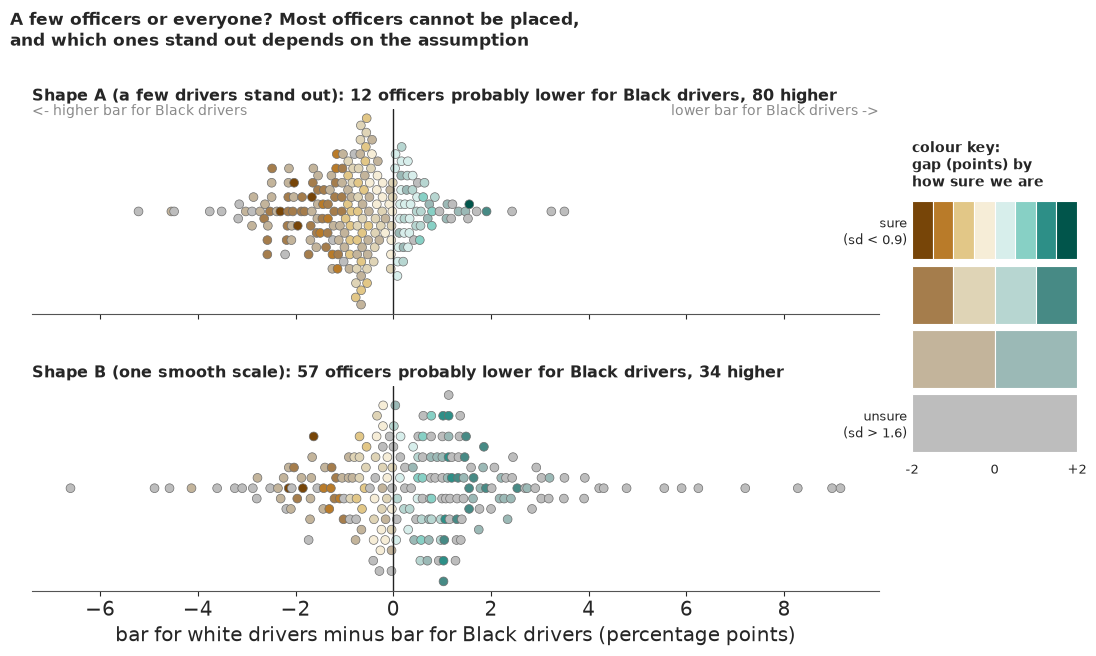

In [24]:
def vsup(val, level, vmax=2.0, k=4, cmap=plt.get_cmap("BrBG")):
    """Value-suppressing colours: uncertainty level j in 0..k-1 keeps 2**(k-1-j) value bins and fades to grey."""
    out = []
    for v, j in zip(val, level):
        nb = 2 ** (k - 1 - j)
        q = (np.floor((np.clip(v, -vmax, vmax - 1e-9) + vmax) / (2 * vmax) * nb) + 0.5) / nb
        c = np.array(cmap(q)[:3])
        out.append(c + (np.array(to_rgb("#bdbdbd")) - c) * j / (k - 1))
    return np.array(out)


G_OFF = {"A": officer_gaps(FIT_A), "B": officer_gaps(FIT_B)}
sd_all = np.r_[G_OFF["A"].std(0), G_OFF["B"].std(0)]
SD_CUTS = np.quantile(sd_all, [0.25, 0.5, 0.75])
print("officer gap posterior sd quartiles (points):", SD_CUTS.round(2))
P_OFF = {fam: (g > 0).mean(0) for fam, g in G_OFF.items()}
flip = ((P_OFF["A"] < 0.1) & (P_OFF["B"] > 0.9)) | ((P_OFF["A"] > 0.9) & (P_OFF["B"] < 0.1))
both = ((P_OFF["A"] < 0.1) & (P_OFF["B"] < 0.1)) | ((P_OFF["A"] > 0.9) & (P_OFF["B"] > 0.9))
print(f"officers sure under both shapes, same side: {both.sum()}; sure under both, opposite sides: {flip.sum()}; "
      f"sure under exactly one: {((P_OFF['A'] < 0.1) | (P_OFF['A'] > 0.9)).sum() + ((P_OFF['B'] < 0.1) | (P_OFF['B'] > 0.9)).sum() - 2 * (both | flip).sum()}")
fig, axs = plt.subplots(2, 1, figsize=(11, 6.6), sharex=True, layout="none")
fig.subplots_adjust(left=0.03, right=0.80, top=0.83, bottom=0.1, hspace=0.35)
for ax, fam in zip(axs, ("A", "B")):
    g = G_OFF[fam]
    med, sd, p = np.median(g, 0), g.std(0), (g > 0).mean(0)
    order = np.argsort(med)
    x = med[order]
    b = np.round(x / 0.12) * 0.12
    y = np.zeros_like(x)
    for v in np.unique(b):
        mk = b == v
        y[mk] = (np.arange(mk.sum()) - (mk.sum() - 1) / 2) * 0.3
    ax.scatter(x, y, s=40, c=vsup(med[order], np.searchsorted(SD_CUTS, sd[order])), edgecolor="#6e6e6e", lw=0.5)
    ax.axvline(0, color=INK, lw=1)
    ax.set_yticks([])
    for s_ in ("left", "right", "top"):
        ax.spines[s_].set_visible(False)
    lab = {"A": "Shape A (a few drivers stand out)", "B": "Shape B (one smooth scale)"}[fam]
    ax.set_title(f"{lab}: {(p > 0.9).sum()} officers probably lower for Black drivers, "
                 f"{(p < 0.1).sum()} higher", loc="left", fontsize=11.5)
axs[1].set_xlabel("bar for white drivers minus bar for Black drivers (percentage points)")
axs[0].text(0.0, 0.97, "<- higher bar for Black drivers", fontsize=10, color=MUTED, transform=axs[0].transAxes)
axs[0].text(1.0, 0.97, "lower bar for Black drivers ->", fontsize=10, color=MUTED, ha="right",
            transform=axs[0].transAxes)
key = fig.add_axes([0.83, 0.3, 0.15, 0.4])
for j in range(4):
    nb = 2 ** (3 - j)
    for i in range(nb):
        v = -2 + (i + 0.5) * 4 / nb
        key.add_patch(Rectangle((i / nb, 3 - j), 1 / nb, 0.9, fc=vsup([v], [j])[0], ec="white", lw=0.8))
key.set_xlim(0, 1)
key.set_ylim(-0.1, 4)
key.set_xticks([0, 0.5, 1], ["-2", "0", "+2"])
key.set_yticks([3.45, 0.45], [f"sure\n(sd < {SD_CUTS[0]:.1f})", f"unsure\n(sd > {SD_CUTS[2]:.1f})"])
key.tick_params(length=0, labelsize=9.5)
for s_ in key.spines.values():
    s_.set_visible(False)
key.set_title("colour key:\ngap (points) by\nhow sure we are", fontsize=10, loc="left")
fig.suptitle("A few officers or everyone? Most officers cannot be placed,\nand which ones stand out depends on "
             "the assumption", x=0.01, ha="left", fontsize=12.5, weight="bold");

Under shape A the strongly coloured dots lean left, brown (more officers with a higher bar for
Black drivers); under shape B they lean right, teal. Grey dots are officers we cannot place; the
pale cream and pale teal ones near zero are officers placed with a small gap. Few dots are
strongly coloured: for most officers, a career of 50-400 searches does not pin down a difference
of a point or two. The printed line says what the shift is made of. No officer is placed on
opposite sides by the two shapes (placed meaning P above 0.9 or below 0.1); 46 are placed on the
same side under both, and 91 are placed under one shape only. The assumption does not reverse
any officer's verdict; it changes *which* officers stand out, and so which side the clearer ones
lean to in total. The public version of the officer question is therefore not a list of names
but this picture: the evidence does not single out a stable group of officers, and the balance
of the ones it does single out depends on the same assumption as the city-wide answer.

### What the public version gains, and what it costs

Against the statistician's two plots the public figures gain three things. They start from
people rather than rates of rates. The gap panel carries the forest plot's numbers with words for
zero and direction and no hard ends, and the ladder makes the distance between hit rate and bar -
the reason the outcome test misleads - visible rather than argued. And they show the model
dependence as two strips and two rows of officers instead of hiding it in a pooled interval. What they lose is the placebo evidence: no picture here says that a wrong shape can
invent a gap with diagnostics that do not single it out. That is carried by the conditional
wording of the title and the confidence statements, and for readers who will act on the numbers,
the "what would change our mind" panel of part F belongs in any briefing. Without it, a single
fit reported with its interval would have said "no bias against Black drivers" under one shape
and "bias" under the other, with equal confidence.

In [25]:
TIMES["total"] = time.time() - T_START
print({k: round(v) for k, v in TIMES.items()})

{'officers A': 47, 'officers A, lower prior': 32, 'years A': 12, 'officers B': 60, 'officers B, lower prior': 41, 'placebo': 132, 'total': 330}


## Summary

- **The hit rate is not the bar.** Two invented groups with the same 10% bar had hit rates of 42%
  and 23%; with a lower bar for the easy-to-read group (7% against 15%), that group still had
  the higher hit rate (36% against 30%). Raleigh's outcome test (Black 16.5%, white 14.2%,
  Hispanic 7.9%) cannot by itself say who faces a lower bar.
- **One unit's two rates cannot place its bar.** For each group, every bar from 0.2% up to just
  below its hit rate reproduces Raleigh's two rates exactly; the threshold test needs many units
  and an additive structure, here 214 officers and a pooled unit for the other 1,384.
- **The level of the bar is soft; the signs are not.** Average bars come out at about 1-3.5%
  under shape A, 3.5-6.5% under B and 5.5-7.5% in the year model, and a ridge leaves the
  race-level means at r_hat 1.04-1.07, while the gaps mix at about 1.02. The default priors put
  hit rates too high; the lower priors that cover the data moved the levels and the Hispanic gap
  in points (2.3 to 1.9 under A, 3.0 to 2.8 under B) and no sign. The rate checks pass, but a
  model with a free bar per cell could not fail them.
- **Hispanic drivers face a lower bar** by about 2.3 points under shape A and 3 under shape B, with
  probability above 99% under each, and about 1.8 in the year model (97%); pooled, about 2.7
  points. The limit: those probabilities are conditional on the shape, and placebo World 1 shows
  a wrong shape can invent a Hispanic gap of about 4 points; the agreement of the two shapes is
  the stronger evidence.
- **For Black drivers the sign depends on the shape.** About -0.3 points under A (a lower bar about
  1 chance in 5) and +0.5 under B (nearly 9 in 10); about -1 and 0 over the 214 named officers
  alone; pooled, about as likely as not, and unlikely over the named officers alone. PSIS-LOO
  could not choose (Pareto k > 0.7 in two thirds of the cells).
- **A wrong shape manufactures gaps, and the diagnostics do not single it out.** In placebo
  worlds with equal bars, both of which fooled the outcome test, the wrong shape found gaps of
  1.2-4 points, near certain; A fitted to World 2 invented a 2.5-point gap with clean diagnostics.
  The one converged right-shape fit missed by about a point, and of eight zero gaps three got
  probabilities above 99%, but the two shapes never agreed on a false gap. The worlds are richer
  in carriers than Raleigh, so they show what can happen, not how much.
- **The public figures** are frequency trees of 10,000 stopped drivers beside gradient strips of
  the gap, a bar-and-hit-rate ladder, a value-suppressing beeswarm of officers and calibrated
  words. None shows that the stops themselves may be biased, which no part of this analysis can
  see.

## Try it yourself

1. **Drop the consent searches.** Rebuild the officer table from `searches - searches_consent`
   and `hits - hits_consent` and refit both shapes. When we tried it while building this
   notebook, shape B's Black-white gap barely moved (about +0.7 points), while the shape A refit
   had about a hundred divergences: can `target_accept=0.95` or a narrower `s_e` prior remove
   them, and what does A then say?
2. **A third shape.** Simoiu et al. (2017) used a beta risk distribution. Write `rates_C` for
   risk $\sim \text{Beta}(\mu\kappa, (1-\mu)\kappa)$, with $S$ and $H$ from the regularised
   incomplete beta function (`pt.betainc`; its gradients are slow, so try it on the year table
   first), and add it to the "what would change our mind" panel. Does it side with A or B on
   Black drivers?
3. **More officers.** Refit with `officer_table(20)`: 454 officers and a smaller pooled unit,
   at 100-170 seconds per fit. Does averaging over named officers only, which now covers more of
   the stops, still move the Black-white gap as much as it does here?